<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="300"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</center></font>
<center><font size=6>Predictive Modeling with Machine Learning and Neural Networks</center></font>

<center><p float="center">
  <img src="https://images.pexels.com/photos/29449341/pexels-photo-29449341.jpeg" alt="health-insurance" width="640"/>
</p></center>
<center><font size=6>Wind Turbine Failure Detection</center></font>

## Note: This is a sample solution for the project. Projects will NOT be graded on the basis of how well the submission matches this sample solution. Projects will be graded on the basis of the rubric only.

# **Problem Statement**

## **Business Context**

Aeolus Renewables is an independent power producer operating a fleet of 1,150 onshore wind turbines (2.5 MW class) across 16 wind farms in the central plains region, with a combined installed capacity of roughly 2.87 GW. The company sells the electricity its turbines produce to the grid under long-term power purchase agreements, where revenue is tied directly to how much energy is delivered - so every hour a turbine is offline is energy that cannot be sold. A regional operations centre monitors the fleet around the clock, supported by an O&M organisation of about 140 field technicians.

Each turbine continuously streams condition data through its SCADA (Supervisory Control and Data Acquisition) system - drivetrain vibration, bearing and oil temperatures, rotor and generator speed, and power output - recorded as 10-minute averages, the standard logging resolution for utility-scale turbines. The exact channels vary by turbine type, but together they describe the health of the main subassemblies in near-real time. Today, maintenance runs on a mix of fixed-interval inspections and reactive repair: technicians follow a scheduled service calendar, and the control room responds when an automated alarm trips or a turbine faults offline.

The most consequential components are in the drivetrain - the gearbox and main bearing - which are expensive, slow to procure, and require a mobile crane to replace. The gearbox alone represents approximately 13% of the overall capital cost of an onshore turbine, and within gearboxes the failures are dominated by bearings: one widely-cited breakdown puts the split at bearings (70%), gears (26%) and other causes (4%). The core problem is recognition. By the time a drivetrain fault has developed far enough to matter, its signature is real but still tangled in normal operating noise across many channels - and the existing fixed thresholds only trip once the fault is near-catastrophic, when the turbine is already offline or the component has seized. A genuinely fault drivetrain can run for hours or days looking "normal" to a threshold alarm, while a control-room analyst has no practical way to tell it apart from a healthy machine reacting to gusty wind. The consequences:

- Each unplanned drivetrain failure takes a turbine offline for an estimated 7–21 days, directly forfeiting saleable energy under the power purchase agreement.
- Emergency crane mobilisation and expedited parts run at a steep premium over the same work scheduled in advance, making an unplanned gearbox replacement a major cost event.
- A degrading main bearing left running frequently destroys the gearbox it feeds, converting a contained repair into a far larger one.
- Control-room analysts manually scan a flood of channels across 1,150 turbines, and alarm fatigue means genuine degradation signals slip through unnoticed until the machine faults offline.


## **Objective**

This proof of concept builds a drivetrain-condition classifier that reads each turbine's live sensor signature and labels the drivetrain as "fault" or "normal," serving operations-centre analysts and maintenance planners.

- Reads each turbine's multi-channel sensor signature and produces a clear fault-vs-normal signal, so analysts can concentrate on the handful of machines genuinely in a fault condition rather than scanning the whole fleet.
- Distinguishes a truly fault drivetrain from normal operating noise more reliably than fixed thresholds, catching faults that are present but not yet severe enough to trip a catastrophic alarm - the window in which a turbine can still be stopped before a bearing fault cascades into gearbox destruction.
Is deliberately tuned to favour catching true failures over avoiding false alerts, because a missed fault drivetrain costs far more than an unnecessary inspection.
- Establishes a measurable detection baseline on historical fleet data, so the capability's accuracy and its operational value can be judged on evidence before any wider rollout.
- Proven at proof-of-concept scale, this capability gives Aeolus a defensible basis to move drivetrain maintenance from reactive repair toward condition-based intervention - reducing unplanned downtime, protecting saleable energy revenue, and containing repairs before they escalate across a 1,150-turbine fleet.


## **Data Dictionary**

The dataset, `wind_turbine_detection.csv` contains 10-minute SCADA records for 15 turbines.

### Identifiers & Metadata

| Column | Data Type | Description |
| --- | --- | --- |
| timestamp | datetime | Date and time of the 10-minute logging interval; establishes chronological sequence. |
| turbine_id | object (categorical) | Unique code identifying individual wind turbines; used to track specific asset history. |

### Environmental Conditions

| Column | Data Type | Description |
| --- | --- | --- |
| rated_power_kW | float | Maximum engineered power capacity of the turbine; defines its performance baseline. |
| wind_speed_mps | float | Velocity of the incoming wind; the primary driver of kinetic energy input. |
| wind_direction_deg | float | Compass direction of oncoming wind; used to assess turbine alignment. |
| turbulence_intensity | float | Measure of wind speed fluctuation; higher intensity increases structural fatigue. |
| air_density_kgm3 | float | Mass of air per unit volume; directly impacts aerodynamic lift and power potential. |
| ambient_temp_C | float | Outdoor air temperature surrounding the turbine; affects cooling efficiency. |
| humidity_pct | float | Relative moisture level in the air; flags risks for electrical insulation degradation or corrosion. |

### Operational Control & State

| Column | Data Type | Description |
| --- | --- | --- |
| power_output_kW | float | Real-time electricity generated; drops or fluctuations can signal mechanical drag. |
| rotor_speed_rpm | float | Rotational speed of the main blades; reflects low-speed shaft dynamics. |
| generator_speed_rpm | float | Rotational speed of the generator shaft; crucial for detecting gearbox slip. |
| blade_pitch_angle_deg | float | Angle of the blades relative to the wind; adjusted to control power and rotor speed. |
| yaw_misalignment_deg | float | Angle deviation between wind direction and nacelle orientation; high values cause uneven drivetrain stress. |

### Thermal Metrics (Component Health)

| Column | Data Type | Description |
| --- | --- | --- |
| gearbox_oil_temp_C | float | Temperature of the lubricating oil; spikes indicate excessive mechanical friction. |
| gearbox_bearing_temp_C | float | Internal temperature of gearbox bearings; a leading indicator of bearing wear. |
| generator_bearing_temp_C | float | Temperature of generator bearings; flags alignment or lubrication issues. |
| generator_winding_temp_C | float | Temperature of internal electrical coils; spikes indicate electrical overload or cooling failure. |
| main_bearing_temp_C | float | Temperature of the primary low-speed shaft bearing; handles massive structural loads. |
| nacelle_temp_C | float | Air temperature inside the enclosed housing; reflects global internal heat dissipation. |

### Vibration & Diagnostics (FFT)

| Column | Data Type | Description |
| --- | --- | --- |
| drivetrain_vibration_rms_mmps | float | Overall energy of drivetrain vibrations; general indicator of mechanical roughness. |
| tower_vibration_mmps | float | Structural oscillation of the turbine tower; flags aerodynamic or rotor imbalance. |
| vib_fft_bearing_bpfo | float | Vibration amplitude at the bearing outer-race defect frequency; tracks outer-ring pitting. |
| vib_fft_bearing_bpfi | float | Vibration amplitude at the bearing inner-race defect frequency; tracks inner-ring pitting. |
| vib_fft_gearmesh | float | Vibration amplitude at the teeth-meshing frequency; isolates gearbox tooth wear or misalignment. |
| vib_fft_sideband | float | Vibration amplitude surrounding main frequencies; flags localized faults like cracked gear teeth. |

### Lubrication & Particle Analysis

| Column | Data Type | Description |
| --- | --- | --- |
| oil_particle_count | float | Quantity of metallic debris suspended in lubricating oil; direct indicator of component wear. |
| oil_pressure_bar | float | Pressure of the lubrication system; drops indicate leaks, pump failures, or oil thinning. |

### Asset Lifecycle & History

| Column | Data Type | Description |
| --- | --- | --- |
| operating_hours_total | float | Cumulative runtime of the turbine; represents the asset's total mechanical mileage. |
| cumulative_energy_MWh | float | Total historical electricity produced; measures the lifetime work done by the drivetrain. |
| load_cycles | int | Total count of fatigue-inducing stress variations; correlates directly with structural aging. |
| hours_since_last_maintenance | float | Time elapsed since last service; crucial for identifying maintenance-cycle fatigue. |
| prior_fault_count | int | Total historical fault events triggered; highlights chronic or poorly repaired issues. |
| component_age_days | float | Elapsed lifetime of active components; captures chronological wear independent of runtime. |

### Targets (Labels)

| Column | Data Type | Description |
| --- | --- | --- |
| failure | int (0/1) | The target variable; boolean flag indicating if the drivetrain or turbine is healthy (0) or failing (1). |

# **Installing and Importing the Necessary Libraries**

In [ ]:
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 tensorflow==2.20.0 keras==3.13.2 xgboost==3.2.0 seaborn==0.13.2 matplotlib==3.10.0 -q

**Note**:
- After running the above cell, kindly restart the notebook kernel (for VS Code) or runtime (for Google Colab), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [ ]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import numpy as np

# Data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tree-based and ensemble machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Utilities for handling class imbalance, model evaluation, and metric calculations
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Deep learning framework and specific layers for building Artificial Neural Networks (ANNs)
import tensorflow as tf
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout, BatchNormalization

# Preprocessing tools for scaling data and tools for model optimization/explainability
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV  # To tune different models
from sklearn.inspection import permutation_importance

# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_style('whitegrid')                     # Set a consistent clean grid style for plots
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes

# **Loading the Data**

In [ ]:
data = pd.read_csv('wind_turbine_detection.csv')

# **Data Overview**

## Viewing the first and last 5 rows of the dataset

In [ ]:
data.head()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
0,1/1/2024 0:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0
1,1/1/2024 0:10,T001,1500,9.166,152.957,0.153,1.200,22.893,74.002,486.762,12.554,1134.433,-0.159,0.489,64.105,67.798,66.841,85.072,58.544,33.649,1.480,0.992,0.455,0.391,0.455,0.399,55.756,5.776,19319.778,9587.227,1.528,769.450,0,1360.710,0
2,1/1/2024 0:20,T001,1500,9.034,158.402,0.201,1.219,22.899,59.616,454.109,12.579,1143.435,1.061,4.220,63.868,66.635,66.093,82.383,58.365,32.667,1.753,1.074,0.455,0.391,0.455,0.399,55.756,5.994,19319.945,9587.302,3.539,769.617,0,1360.717,0
3,1/1/2024 0:30,T001,1500,13.284,159.023,0.159,1.181,22.727,64.676,1446.811,16.941,1526.358,5.718,1.584,83.654,89.761,85.749,128.484,77.257,36.349,1.924,1.379,0.455,0.391,0.455,0.399,55.756,5.541,19320.112,9587.544,5.126,769.784,0,1360.724,0
4,1/1/2024 0:40,T001,1500,2.239,159.842,0.189,1.173,23.742,65.423,0.000,0.194,27.405,88.452,3.400,54.573,57.150,56.817,60.963,51.506,32.234,1.497,0.936,0.455,0.391,0.455,0.399,55.756,6.018,19320.112,9587.544,5.126,769.950,0,1360.731,0


In [ ]:
data.tail()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
131755,3/1/2024 23:10,T015,3000,5.680,108.327,0.306,1.200,19.599,60.093,95.437,8.399,764.196,-0.123,-6.325,53.286,60.399,56.996,63.265,50.056,27.808,2.139,0.886,0.322,0.333,0.424,0.224,78.731,5.741,36147.152,33527.459,13588.408,2588.506,63,784.507,0
131756,3/1/2024 23:20,T015,3000,6.945,111.198,0.151,1.207,18.800,63.952,254.325,9.789,886.754,0.507,1.873,54.811,62.961,60.368,67.812,50.091,27.891,1.470,0.956,0.322,0.333,0.424,0.224,78.731,6.125,36147.318,33527.501,13589.919,2588.673,63,784.514,0
131757,3/1/2024 23:30,T015,3000,2.191,113.020,0.148,1.214,18.331,61.764,0.000,0.029,3.975,87.072,0.880,51.704,60.440,57.181,63.706,47.760,26.242,1.793,0.897,0.322,0.333,0.424,0.224,78.731,5.955,36147.318,33527.501,13589.919,2588.839,63,784.521,0
131758,3/1/2024 23:40,T015,3000,11.003,117.356,0.178,1.200,19.640,62.729,2056.378,14.527,1297.923,0.869,4.662,72.463,84.704,78.389,111.169,66.612,31.989,1.764,1.212,0.322,0.333,0.424,0.224,78.731,5.920,36147.485,33527.844,13591.700,2589.006,63,784.528,0
131759,3/1/2024 23:50,T015,3000,2.231,116.146,0.160,1.206,19.598,66.575,0.000,0.040,0.936,88.206,0.105,51.646,60.774,57.721,63.360,46.512,28.247,1.833,1.239,0.322,0.333,0.424,0.224,78.731,5.886,36147.485,33527.844,13591.700,2589.173,63,784.535,0


**Observations**

- Each row is one **10-minute interval** for a turbine (`T001`-`T015`); the data spans **Jan 1 - Mar 1, 2024**.
- `timestamp` and `turbine_id` are text, `rated_power_kW` is an integer, and the sensor channels are numeric - consistent with the data dictionary.

## Checking the shape of the dataset

In [ ]:
data.shape

(131760, 35)

- The dataset has **131,760 rows and 35 columns**.
- These are 10-minute SCADA records for **15 turbines** (T001–T015), each contributing **8,784 rows** spanning **Jan 1 – Mar 1, 2024**.

## Checking the attribute types

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131760 entries, 0 to 131759
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   timestamp                      131760 non-null  object 
 1   turbine_id                     131760 non-null  object 
 2   rated_power_kW                 131760 non-null  int64  
 3   wind_speed_mps                 131760 non-null  float64
 4   wind_direction_deg             131760 non-null  float64
 5   turbulence_intensity           131760 non-null  float64
 6   air_density_kgm3               131760 non-null  float64
 7   ambient_temp_C                 131760 non-null  float64
 8   humidity_pct                   131760 non-null  float64
 9   power_output_kW                131760 non-null  float64
 10  rotor_speed_rpm                131760 non-null  float64
 11  generator_speed_rpm            131760 non-null  float64
 12  blade_pitch_angle_deg         

- The dataset spans **35 columns**: a datetime stamp, two identifiers (`timestamp`, `turbine_id`), a large block of numeric SCADA channels (environment, power/rotation, drivetrain temperatures, vibration and FFT bands, oil, and cumulative wear counters), and the binary target `failure`.
- Most channels are numeric `float64`; the three text (`object`) columns are `timestamp` and `turbine_id`
- A few sensor columns contain missing values (handled below), unlike a fully populated table.

## Checking the statistical summary

In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rated_power_kW,131760.0,2166.666667,743.567808,1500.000,1500.00000,2000.0000,3000.00000,3600.000
wind_speed_mps,131760.0,7.649297,4.066898,0.015,4.62700,7.1365,10.08800,32.000
wind_direction_deg,131760.0,163.155270,106.644769,0.000,68.28875,150.5440,254.89200,359.995
turbulence_intensity,131760.0,0.175353,0.033725,0.121,0.15100,0.1680,0.19100,0.450
air_density_kgm3,131760.0,1.244980,0.037329,1.140,1.21400,1.2450,1.27600,1.345
ambient_temp_C,131760.0,10.011035,8.999438,-9.748,2.17800,9.9770,17.85900,29.078
humidity_pct,131760.0,60.023310,13.067340,18.908,50.03800,59.9980,70.00800,99.693
power_output_kW,131760.0,633.607766,869.596264,0.000,17.35800,198.5185,1014.10925,3672.000
rotor_speed_rpm,131760.0,9.981842,4.856042,0.000,7.30700,10.1970,13.59600,17.628
generator_speed_rpm,131760.0,898.629973,436.640301,0.000,657.56950,917.7410,1223.73300,1590.833


* **Operating regime & power:** The fleet spends most of its time generating - `power_output_kW` and the rotation channels show a wide active range with a substantial mass at zero (idle/curtailed). `rated_power_kW` is constant per turbine class.
* **Drivetrain condition channels:** `drivetrain_vibration_rms_mmps`, the four `vib_fft_*` bands, the bearing/gearbox temperatures, and `oil_particle_count` are the physically meaningful health signals. Their upper tails extend well beyond the median, which is exactly where fault behaviour is expected to live.
* **Wear context:** Cumulative counters (`operating_hours_total`, `cumulative_energy_MWh`, `load_cycles`, `component_age_days`, `prior_fault_count`) vary far more *between* turbines than within the two-month window, acting as slow-moving wear context.

## Checking for missing values

In [ ]:
data.isnull().sum()

,0
timestamp,0
turbine_id,0
rated_power_kW,0
wind_speed_mps,0
wind_direction_deg,0
turbulence_intensity,0
air_density_kgm3,0
ambient_temp_C,0
humidity_pct,0
power_output_kW,0


- Three sensor channels carry missing values: **`gearbox_oil_temp_C` (645)**, **`generator_bearing_temp_C` (690)**, and **`oil_pressure_bar` (636)** - about 0.5% of rows each. Their pattern looks like **random sensor dropout**: the missing rows follow the same operating-mode mix as the full data (~84% running) and their failure rate (≈2.5–3.9%) is close to the 3.0% baseline, so the gaps are not tied to drivetrain condition.

## Checking for duplicate values

In [ ]:
data.duplicated().sum()

np.int64(0)

* There are **no duplicate rows** in the data.

# **Data Preprocessing**

As we saw that the datetime values are in a different string format, we first need to convert them into a proper datetime data type so that pandas can interpret and manipulate them correctly. To do this, we will parse the timestamp column using the appropriate format string and store the result back into the same column:

In [ ]:
data["timestamp"] = pd.to_datetime(data["timestamp"], format="%m/%d/%Y %H:%M")

- Once this conversion is done, we can easily extract useful time-based features from it.
- Now, we can create new columns for the day of the week and the hour of day, which can help in understanding temporal patterns in the data

In [ ]:
data["dayofweek"] = data["timestamp"].dt.dayofweek

In [ ]:
data["hour"] = data["timestamp"].dt.hour

# **Exploratory Data Analysis**

## Utility Functions

In [ ]:
def histogram(data_df, col, title='Histogram', xlabel=None, ylabel='Frequency'):
    plt.figure(figsize=(9, 3.6))
    sns.histplot(data_df[col], bins=50, kde=True)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else col)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

def barchart(data_df, x_col, y_col=None, title='Bar Chart', xlabel=None, ylabel=None, rot_degrees=30):
    plt.figure(figsize=(10, 6))
    if y_col: # Bivariate bar chart (x vs y)
        sns.barplot(x=x_col, y=y_col, data=data_df)
    else: # Univariate count plot
        order = data_df[x_col].value_counts().index
        sns.countplot(data=data_df, x=x_col, order=order)

    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else ('Count' if not y_col else y_col))
    plt.xticks(rotation=rot_degrees, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def boxplot(data_df, x_col, y_col, title='Box Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.boxplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

def scatterplot(data_df, x_col, y_col, title='Scatter Plot', xlabel=None, ylabel=None):
    plt.figure(figsize=(6, 3.8))
    sns.scatterplot(data=data_df, x=x_col, y=y_col)
    plt.title(title)
    plt.xlabel(xlabel if xlabel else x_col)
    plt.ylabel(ylabel if ylabel else y_col)
    plt.tight_layout()
    plt.show()

## Univariate Analysis

### `failure`

- This is the most important business outcome variable, indicating whether the turbine experienced a failure event. Understanding its distribution provides insight into the overall reliability of the fleet and establishes the baseline failure rate.
- Since reducing failures directly improves turbine availability, maintenance efficiency, and operational profitability, this feature is central to predictive maintenance and reliability analysis.

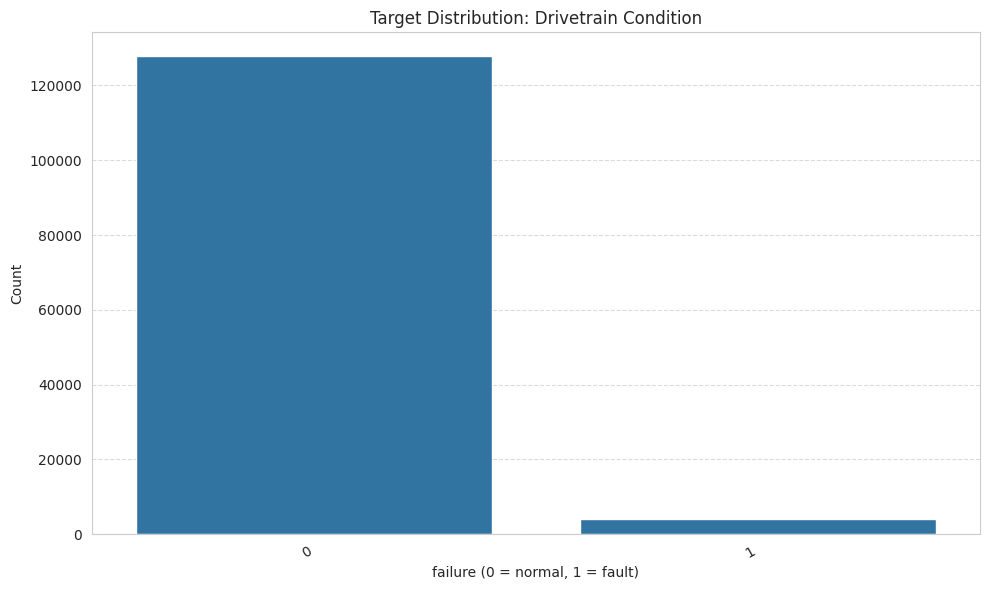

In [ ]:
barchart(data, 'failure', title='Target Distribution: Drivetrain Condition', xlabel='failure (0 = normal, 1 = fault)')

**Observations**

* Highly **imbalanced**: ~**97% normal / ~3% fault** (3,953 of 131,760).
* Accuracy alone would be misleading (predicting 'normal' always scores ~97%); evaluation must lean on **recall, precision, and F1**, and the imbalance motivates the recall-first criterion.

### ```wind_speed_mps```

- Wind speed is the primary environmental driver of turbine performance because the energy available in the wind increases rapidly with speed. It directly influences rotor rotation, generator speed, and power output.
- Analyzing its distribution helps determine whether the turbine typically operates below cut-in speed, within the optimal operating range, or near cut-out conditions where safety shutdowns occur.

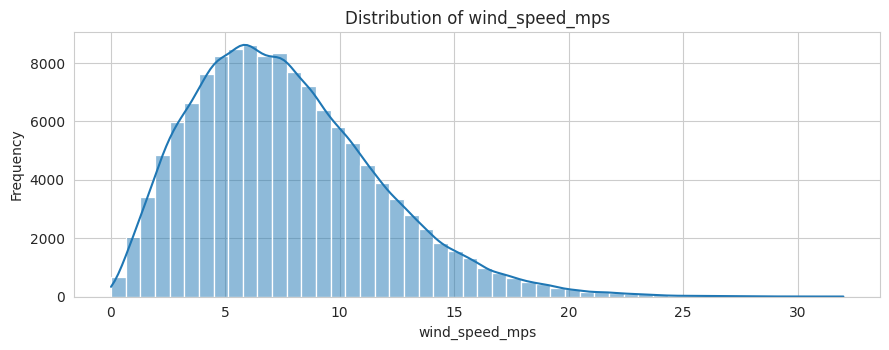

In [ ]:
histogram(data, 'wind_speed_mps', title='Distribution of wind_speed_mps', xlabel='wind_speed_mps')

**Observations**

* The distribution of **`wind_speed_mps`** is **positively (right) skewed**, with most observations concentrated between **4 and 10 m/s**. This indicates that moderate wind conditions occur most frequently, representing the turbine's typical operating environment.

* The frequency gradually decreases as wind speed increases, with very few observations above **20 m/s** and only a small number beyond **25 m/s**. This reflects the natural rarity of extreme wind events and explains why turbine cut-out conditions are observed only occasionally in the dataset.

### ```air_density_kgm3```

- Air density determines how much energy is contained in the wind. Even at the same wind speed, denser air carries more kinetic energy, allowing the turbine to generate more electricity.
- Air density varies with temperature, altitude, and atmospheric pressure, making it an important environmental factor when evaluating turbine performance and comparing energy production across different condition

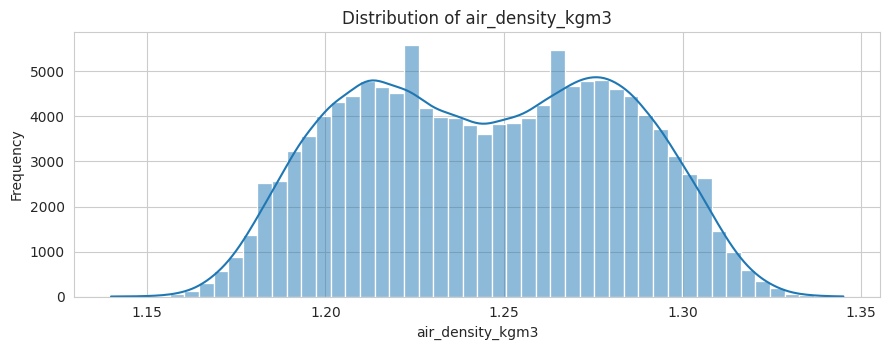

In [ ]:
histogram(data, 'air_density_kgm3', title='Distribution of air_density_kgm3', xlabel='air_density_kgm3')

**Observations**

* The distribution of **`air_density_kgm3`** appears **bimodal**, with two noticeable peaks around **1.21 kg/m³** and **1.28 kg/m³**. This suggests the turbine operated under two distinct atmospheric conditions, which may correspond to different weather patterns or seasonal variations.

* Most air density values fall within the narrow range of **1.19–1.30 kg/m³**, indicating relatively stable environmental conditions. Since higher air density increases the available wind energy, periods with higher air density are expected to support slightly greater power generation at the same wind speed.


### ```gearbox_oil_temp_C```

- The gearbox is one of the most expensive components in a wind turbine. Gearbox oil temperature reflects both mechanical loading and lubrication effectiveness. Elevated temperatures may indicate excessive friction, inadequate lubrication, or developing gearbox faults.
- Understanding its distribution helps assess whether the gearbox consistently operates within a safe thermal range or experiences conditions that may shorten its service life.

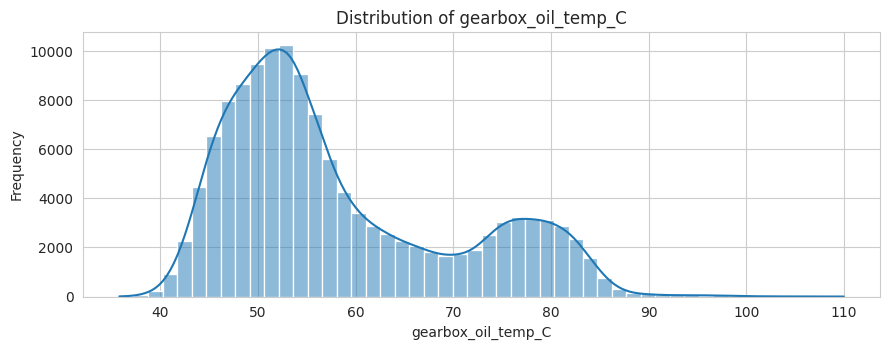

In [ ]:
histogram(data, 'gearbox_oil_temp_C', title='Distribution of gearbox_oil_temp_C', xlabel='gearbox_oil_temp_C')

**Observations**

* The distribution of **`gearbox_oil_temp_C`** is **bimodal**, with a dominant peak around **50–55°C** and a smaller secondary peak around **75–80°C**. This suggests the gearbox primarily operates under normal thermal conditions but also experiences periods of higher loading, leading to elevated oil temperatures.

* Most gearbox oil temperatures fall between **45°C and 85°C**, with very few observations above **90°C**. The small number of high-temperature readings indicates that overheating events are relatively rare, suggesting the gearbox generally operates within a safe thermal range while occasionally encountering higher mechanical loads or demanding operating conditions.


### ```generator_winding_temp_C```

- Generator winding temperature indicates the thermal condition of the electrical generator. As electrical load increases, winding temperatures naturally rise, but excessive temperatures accelerate insulation degradation and increase the likelihood of generator failure.
- Examining its distribution helps evaluate whether the generator typically operates within safe thermal limits or is frequently exposed to overheating conditions.

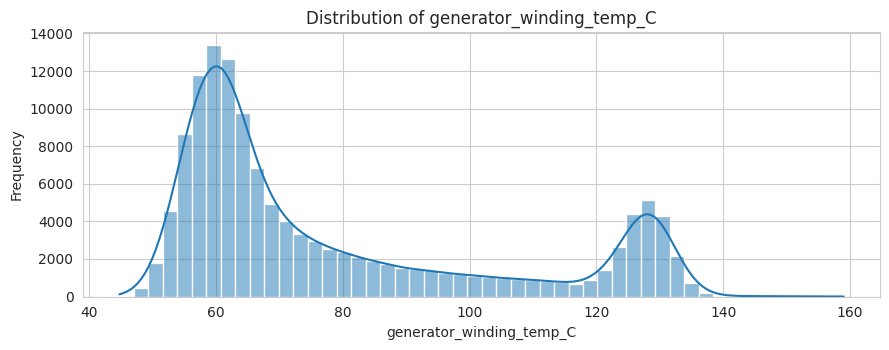

In [ ]:
histogram(data, 'generator_winding_temp_C', title='Distribution of generator_winding_temp_C', xlabel='generator_winding_temp_C')

**Observations**

* Major peak around **58–62°C** and a smaller peak around **125–130°C**. This indicates the generator operates under two distinct thermal conditions, representing normal operating temperatures and periods of higher electrical loading.

* Most observations fall within the **55–70°C** range, while a smaller proportion of readings occur at elevated temperatures between **120°C and 130°C**. The limited number of high-temperature observations suggests that the generator generally operates within safe thermal limits, with occasional periods of increased thermal stress that may warrant closer monitoring to prevent insulation degradation and premature component failure.


### ```drivetrain_vibration_rms_mmps```

- Drivetrain vibration is one of the most valuable condition monitoring indicators for mechanical health. Abnormally high vibration often signals issues such as bearing wear, shaft misalignment, imbalance, or gearbox defects before they result in catastrophic failures.
- Monitoring its distribution helps identify whether the turbine generally operates smoothly or experiences periods of excessive mechanical stress.

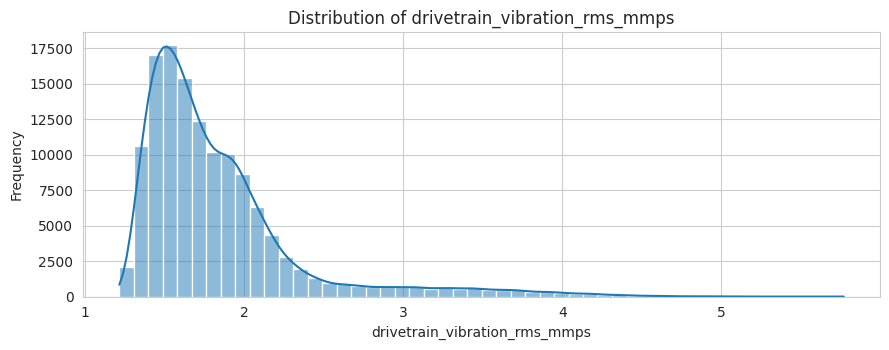

In [ ]:
histogram(data, 'drivetrain_vibration_rms_mmps', title='Distribution of drivetrain_vibration_rms_mmps', xlabel='drivetrain_vibration_rms_mmps')

**Observations**

* Most vibration levels concentrated between **1.4 and 2.0 mm/s**. This indicates that the drivetrain generally operates under stable mechanical conditions with relatively low vibration, which is expected during normal turbine operation.

* The long right tail extending beyond **4 mm/s** represents a small number of higher vibration events. These elevated vibration levels are relatively infrequent but may indicate periods of increased mechanical loading, component imbalance, bearing wear, or developing drivetrain faults, making them important candidates for condition monitoring and predictive maintenance.


### ```tower_vibration_mmps```

- Tower vibration tracks the structural oscillation of the turbine's supporting tower rather than the drivetrain itself. It rises with aerodynamic loading, rotor imbalance, and yaw activity, making it a read on how hard the structure is being worked.
- Where drivetrain vibration speaks to gearbox and bearing wear, tower vibration speaks to structural and rotor-balance health, so its distribution tells us how stable the tower is in normal operation and how often it sees heavier loading.

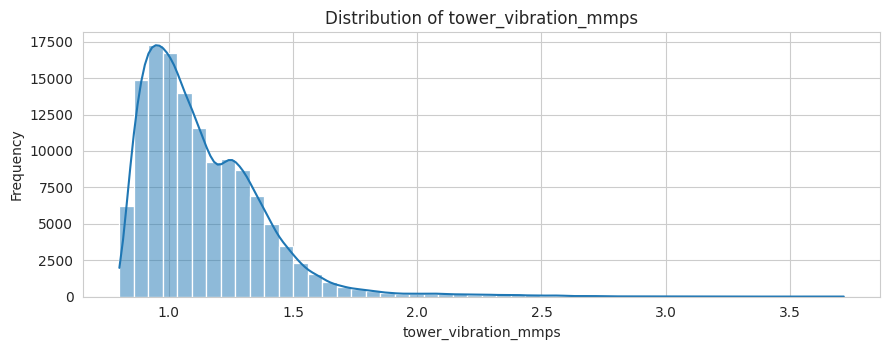

In [ ]:
histogram(data, 'tower_vibration_mmps', title='Distribution of tower_vibration_mmps', xlabel='tower_vibration_mmps')

**Observations**

* Most observations concentrated between **0.9 and 1.4 mm/s**. This indicates that the tower generally experiences low vibration levels, suggesting stable structural performance during normal operating conditions.

* A long right tail extends beyond **2.0 mm/s**, although such observations are relatively infrequent. These higher vibration levels may occur during periods of strong winds, increased turbulence, or abnormal operating conditions, making them important to monitor as they could indicate elevated structural loading or the onset of mechanical issues.


### ```oil_particle_count```

- Oil particle count measures the metallic debris suspended in the gearbox lubricating oil - one of the most direct wear indicators available. Healthy components shed almost no metal; as gears pit or bearings spall, steel and copper flakes accumulate in the oil.
- Its distribution shows the baseline debris level during normal operation and how often the count climbs into the elevated range that flags accelerating wear - an early, physical signature of a developing drivetrain fault.

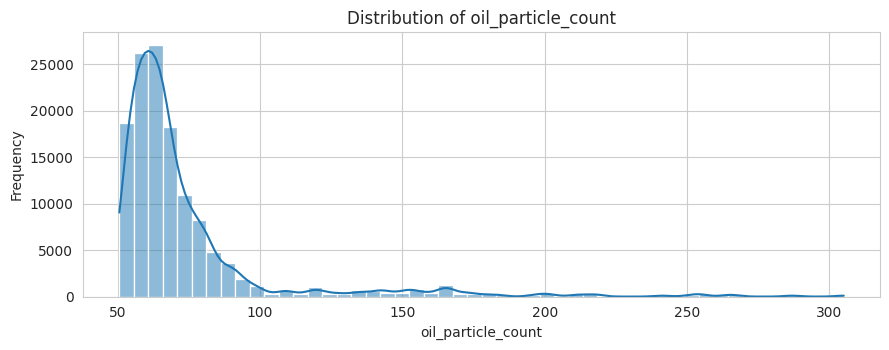

In [ ]:
histogram(data, 'oil_particle_count', title='Distribution of oil_particle_count', xlabel='oil_particle_count')

**Observations**

* Most observations concentrated between **55 and 80 particles**. This indicates that the gearbox generally operates under normal wear conditions, with relatively low levels of metallic debris present in the lubricating oil.

* A long right tail extends beyond **100 particles**, with a small number of observations reaching **300 particles**. These elevated particle counts are relatively rare but may indicate accelerated gearbox wear, lubrication issues, or developing component degradation, making them valuable early warning indicators for predictive maintenance and failure prevention.


### ```prior_fault_count```

History repeats - turbines that failed before fail again. A "this asset is a repeat offender" flag that's extremely intuitive for a maintenance manager.

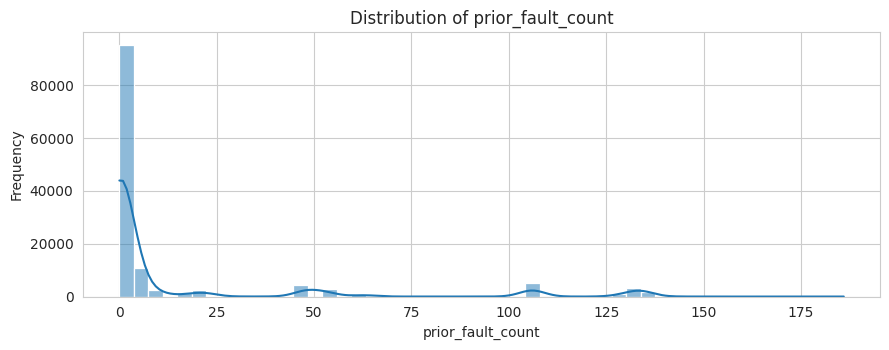

In [ ]:
histogram(data, 'prior_fault_count', title='Distribution of prior_fault_count', xlabel='prior_fault_count')

**Observations**

* Vast majority of observations concentrated at **very low fault counts**. This indicates that most turbines have experienced few or no prior faults, suggesting the fleet generally operates under reliable conditions with limited historical failures.

* A small number of turbines exhibit **substantially higher prior fault counts**, creating a long right tail. These high-fault turbines represent a minority of the fleet but may indicate recurring equipment issues, aging components, or increased maintenance requirements, making them important candidates for reliability assessment and predictive maintenance.
- A single unfixed or poorly repaired minor fault physically strains adjacent components, leading to a cascade of subsequent faults.


### ```component_age_days```

- Component age captures the calendar lifetime of a turbine's active components, independent of how many hours they have actually run. It is slow-moving wear context: older components carry more accumulated fatigue and are statistically more failure-prone.
- Examining its distribution tells us whether the fleet's components were installed steadily over time or in distinct batches - which in turn shapes how age maps to failure risk across the fleet.

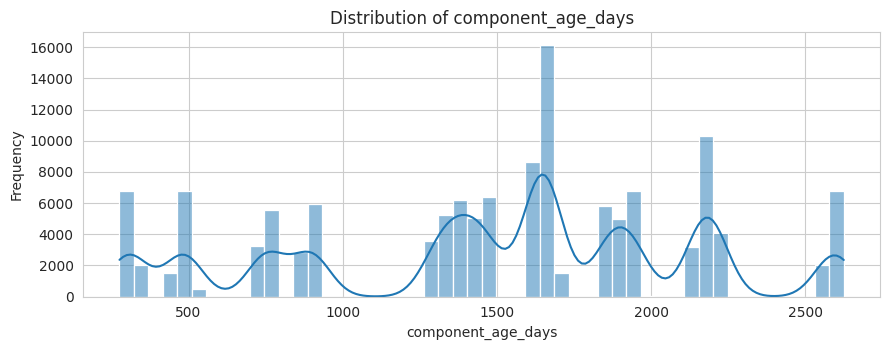

In [ ]:
histogram(data, 'component_age_days', title='Distribution of component_age_days', xlabel='component_age_days')

**Observations**

* The distribution is **multimodal**, forming several distinct clusters of component ages rather than one smooth curve. This suggests that turbine components were installed or replaced in batches, resulting in groups of components with similar ages instead of a uniform age profile across the fleet.

* Most components fall within the **1,300–2,300 day** range, indicating that a large portion of the fleet consists of mature components with significant operational history. Smaller groups of newer components likely represent recent replacements or maintenance activities, while older components may require closer monitoring due to their increased likelihood of wear and failure.

## Bivariate Analysis

### ```failure``` vs ```hour```

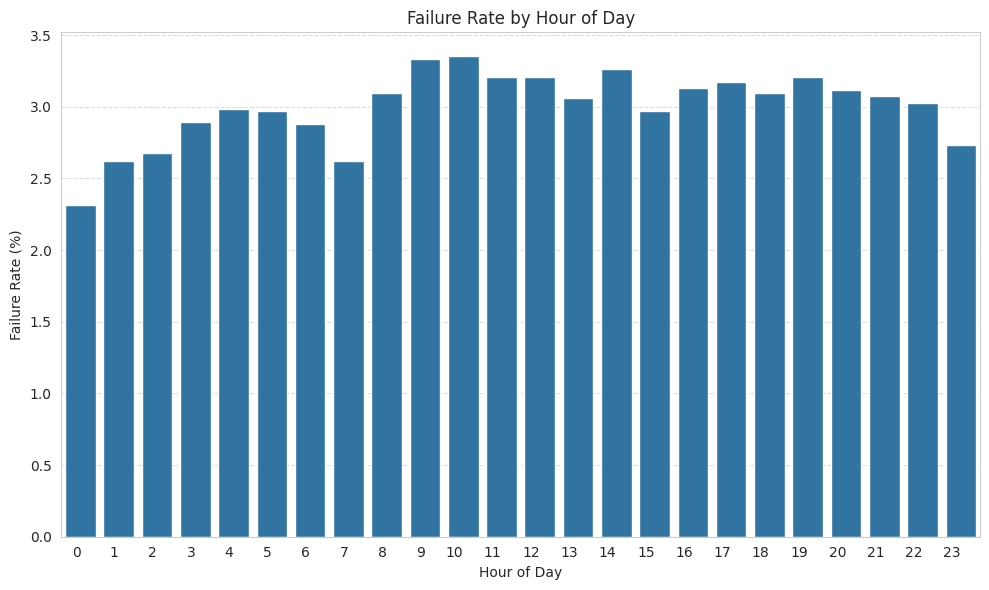

In [ ]:
# Calculate failure rate by hour
failure_rate_by_hour_df = data.groupby('hour')['failure'].mean().reset_index()
failure_rate_by_hour_df['failure_rate_pct'] = failure_rate_by_hour_df['failure'] * 100

# Plot using the barchart utility function
barchart(data_df=failure_rate_by_hour_df, x_col='hour', y_col='failure_rate_pct',
         title='Failure Rate by Hour of Day',
         xlabel='Hour of Day', ylabel='Failure Rate (%)', rot_degrees=0)

* **Morning Ramp-Up Peak (Hours 9–10):** Failure rates peak above 3.3% during the morning grid demand surge, where rapid dynamic loading and blade pitching trigger latent mechanical and electrical faults.
* **Nocturnal Stress & Shift Dip (Hours 1–7):** Failures rise overnight due to sustained nocturnal wind fatigue, but drop sharply at Hour 7 when morning maintenance crews arrive to clear sensor faults and perform system resets.

### ```failure``` vs ```dayofweek```

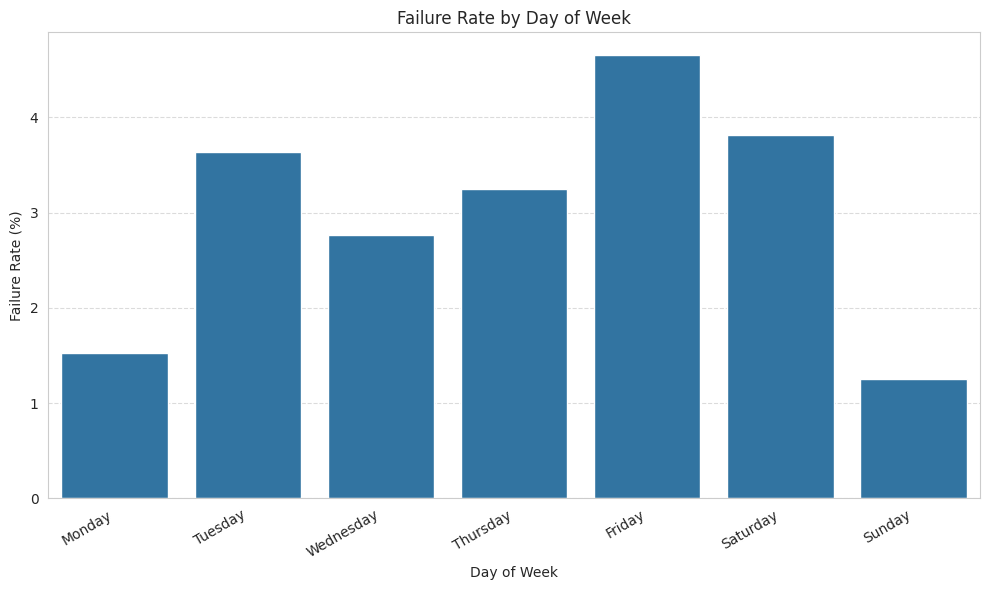

In [ ]:
failure_rate_by_day_df = data.groupby('dayofweek')['failure'].mean().reset_index()
failure_rate_by_day_df['failure_rate_pct'] = failure_rate_by_day_df['failure'] * 100
# Define the chronological order of days for sorting
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Map numerical dayofweek to names
day_name_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
failure_rate_by_day_df['dayofweek'] = failure_rate_by_day_df['dayofweek'].map(day_name_map)

# Convert 'dayofweek' to a categorical type with the defined order
failure_rate_by_day_df['dayofweek'] = pd.Categorical(failure_rate_by_day_df['dayofweek'], categories=day_order, ordered=True)

# Sort the DataFrame by the ordered 'dayofweek'
failure_rate_by_day_df = failure_rate_by_day_df.sort_values('dayofweek')

barchart(data_df=failure_rate_by_day_df, x_col='dayofweek', y_col='failure_rate_pct',
         title='Failure Rate by Day of Week',
         xlabel='Day of Week', ylabel='Failure Rate (%)', rot_degrees=30)

* **Friday Peak (~4.6%):** Failure rates peak at the end of the traditional workweek, likely driven by the accumulation of component stress from consecutive days of high industrial power demand and a rush to log pending maintenance issues before the weekend.
* **Sunday Operational Lull (~1.2%):** Sunday exhibits the lowest failure rate, correlating with reduced commercial grid demand, fewer operational adjustments, and minimal on-site maintenance activity or manual fault logging.

### ```turbine_id``` vs ```failure```

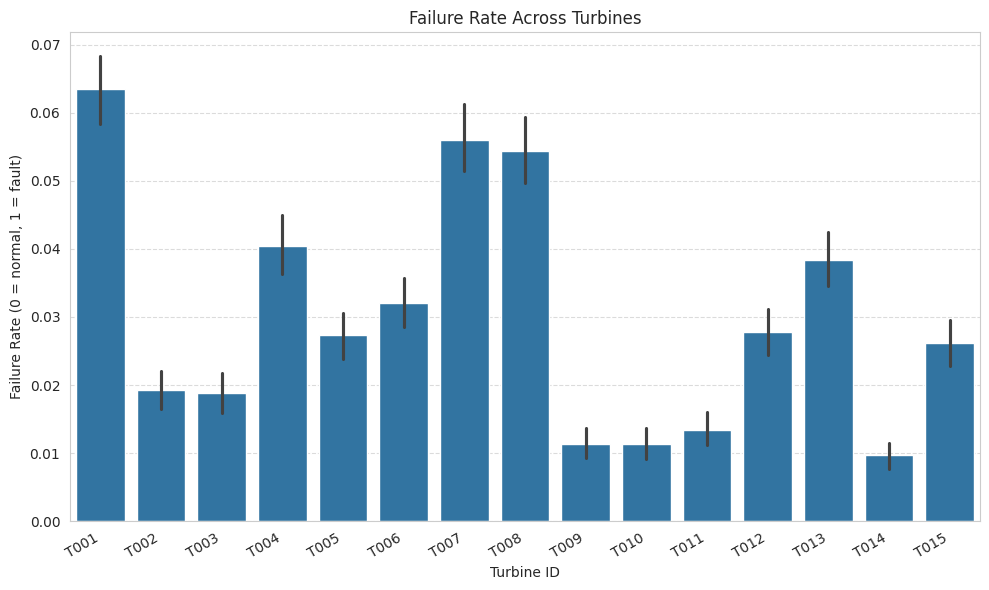

In [ ]:
barchart(data_df=data, x_col='turbine_id', y_col='failure', title='Failure Rate Across Turbines', xlabel='Turbine ID', ylabel='Failure Rate (0 = normal, 1 = fault)')

**Observations**

* Failure rates are **not uniform across the fleet** - some turbines contribute a markedly higher share of fault records than others, rather than every machine sitting near the ~3% fleet average.

* This echoes the **repeat-offender pattern** seen earlier in `prior_fault_count`: a minority of assets carry a disproportionate amount of the failure history, likely reflecting aging components or incompletely resolved past faults. It confirms that *failure history* is a real risk signal - though we deliberately drop `turbine_id` itself before modelling, so the model learns transferable sensor signatures rather than memorising which specific machines failed.

### `wind_speed_mps` vs `power_output_kW`

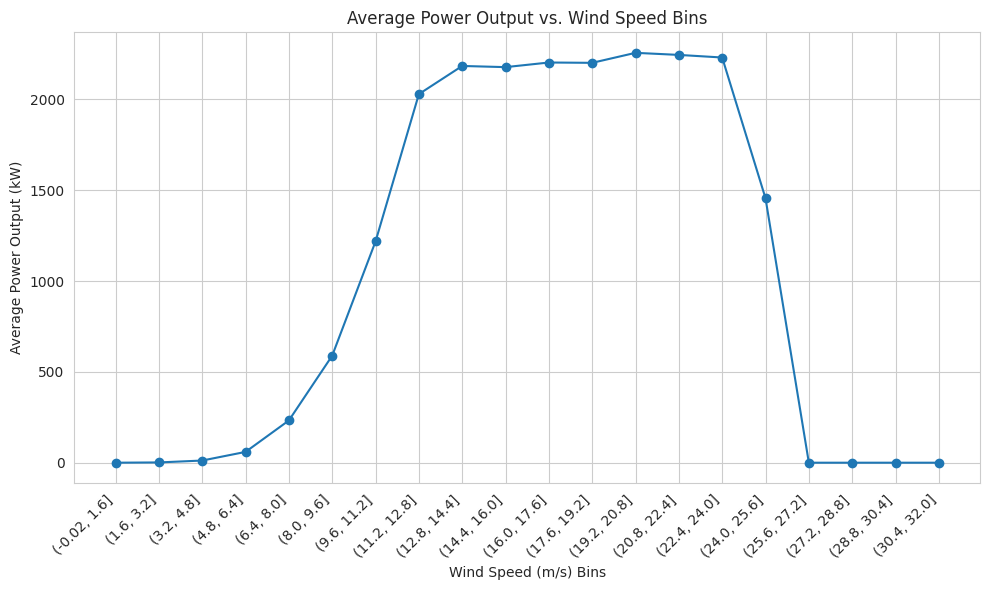

In [ ]:
wind_speed_bins = pd.cut(data['wind_speed_mps'], bins=20, precision=1)
power_output_mean = data.groupby(wind_speed_bins)['power_output_kW'].mean()

plt.figure(figsize=(10, 6))
plt.plot(power_output_mean.index.astype(str), power_output_mean.values, marker='o')
plt.xlabel('Wind Speed (m/s) Bins')
plt.ylabel('Average Power Output (kW)')
plt.title('Average Power Output vs. Wind Speed Bins')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

* The power curve follows the expected wind turbine behavior: power output increases rapidly with wind speed, reaches its rated capacity of approximately **2200–2300 kW** around **12–14 m/s**, and remains stable across a wide operating range.

* Beyond **25–26 m/s**, power output drops to nearly zero because the turbine enters **cut-out/curtailed mode** for safety, indicating that high wind conditions lead to turbine shutdown rather than increased energy generation.


### ```rotor_speed_rpm``` vs ```generator_speed_rpm```

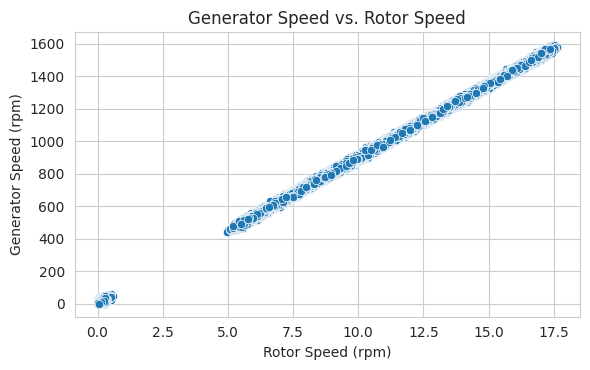

In [ ]:
scatterplot(data_df=data, x_col='rotor_speed_rpm', y_col='generator_speed_rpm',
            title='Generator Speed vs. Rotor Speed',
            xlabel='Rotor Speed (rpm)',
            ylabel='Generator Speed (rpm)')

-  In a standard wind turbine, the generator speed increases proportionally as the rotor speed increases because they are mechanically linked through a fixed-ratio transmission system
- The clear gap between 0 and 5 rpm suggests the turbine operates in two distinct modes: idle/shutdown and active power generation. The absence of observations in the transition region indicates that startup occurs quickly and the turbine rarely remains at intermediate rotor speeds.

### ```wind_speed_mps``` vs ```rotor_speed_rpm```

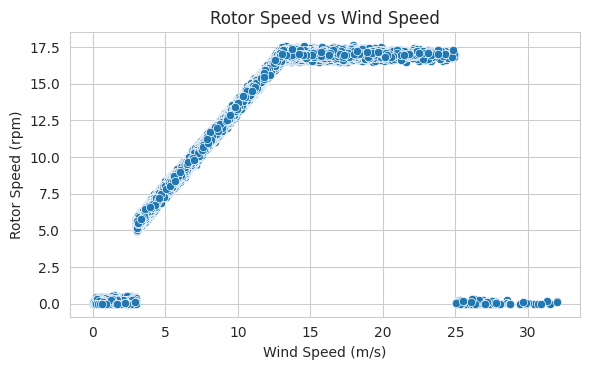

In [ ]:
scatterplot(data_df=data, x_col='wind_speed_mps', y_col='rotor_speed_rpm',
            title='Rotor Speed vs Wind Speed',
            xlabel='Wind Speed (m/s)',
            ylabel='Rotor Speed (rpm)')

- The rotor speed increases almost linearly with wind speed from approximately 3 m/s to 13 m/s, indicating the turbine is operating in the variable-speed region where the control system adjusts rotor speed to maximize energy capture.
- A distinct cluster of observations appears near 0 rpm for wind speeds below 3 m/s, representing conditions below the turbine's cut-in wind speed where insufficient wind energy is available to drive the rotor.
- The cluster of observations between 25–32 m/s wind speed and 0 rpm rotor speed indicates the turbine has entered its cut-out safety region. Instead of continuing to spin faster as wind speed increases, the control system stops the rotor to prevent equipment damage during extreme wind conditions

### `drivetrain_vibration_rms_mmps` vs `failure`

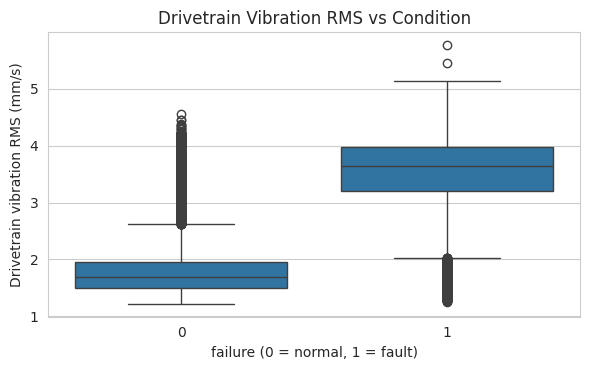

In [ ]:
boxplot(data, x_col='failure', y_col='drivetrain_vibration_rms_mmps', title='Drivetrain Vibration RMS vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Drivetrain vibration RMS (mm/s)')

**Observations**

* fault drivetrains show a **markedly higher median vibration (~3.6 mm/s vs ~1.7 mm/s for normal - roughly 2.2x)**, with a much wider spread.
* This is the clearest single separator in the data and aligns with the physics: mechanical wear raises broadband vibration.

### `oil_particle_count` vs `failure`

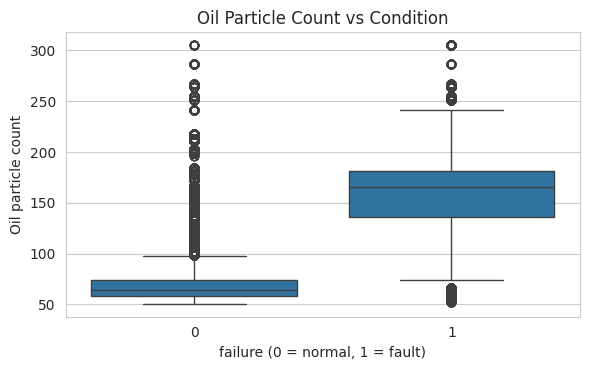

In [ ]:
boxplot(data, x_col='failure', y_col='oil_particle_count', title='Oil Particle Count vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Oil particle count')

**Observations**

* fault rows have a **much higher median particle count (~165 vs ~64 - about 2.6x)** and a long high-debris tail.
* When a mechanical fault begins-such as gear tooth pitting, bearing spalling, or micro-cracking-metal-on-metal tearing occurs. The component sheds macroscopic steel and copper flakes into the oil. This causes the localized particle count to skyrocket, explaining the 2.6x increase in the median.

### `gearbox_bearing_temp_C` vs `failure`

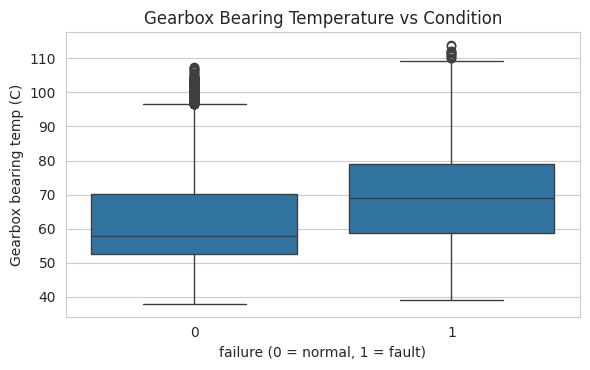

In [ ]:
boxplot(data, x_col='failure', y_col='gearbox_bearing_temp_C', title='Gearbox Bearing Temperature vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Gearbox bearing temp (C)')

**Observations**

* fault drivetrains run **warmer at the gearbox bearing (median ~69 C vs ~58 C)**, consistent with increased friction from wear.
* The separation is real but smaller than vibration/oil, so temperature is best used as a corroborating rather than standalone signal.

### `power_output_kW` vs `failure`

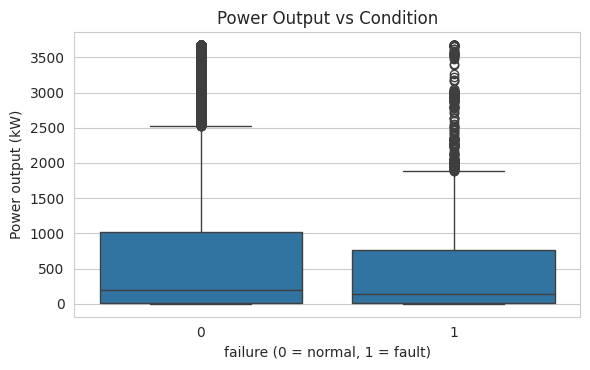

In [ ]:
boxplot(data, x_col='failure', y_col='power_output_kW', title='Power Output vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Power output (kW)')

**Observations**

* fault rows tend to deliver **lower median power (~137 kW vs ~201 kW)**, reflecting reduced or interrupted generation as faults develop.
* This makes power a useful contextual feature, though it is also influenced by wind resource and curtailment.

### `prior_fault_count` vs `failure`

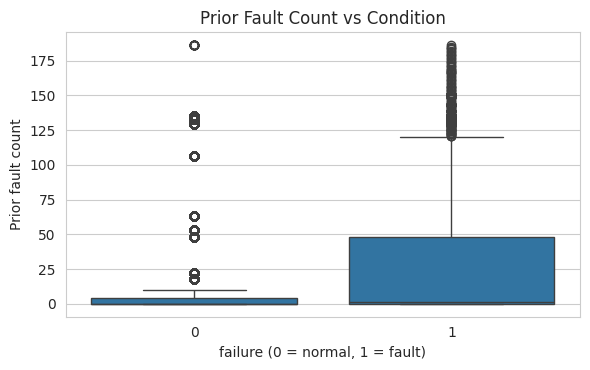

In [ ]:
boxplot(data, x_col='failure', y_col='prior_fault_count', title='Prior Fault Count vs Condition', xlabel='failure (0 = normal, 1 = fault)', ylabel='Prior fault count')

**Observations**

* fault rows carry a **higher prior fault count (median ~1 vs 0)**, indicating that machines with a history of faults are more likely to be in a fault state.
* This is legitimate wear/history context rather than leakage, since it reflects information available before the current assessment.

## Multivariate Analysis

### Correlation Analysis

Understanding how channels move together helps spot redundancy, physically expected couplings, and potential leakage before modelling.

In [ ]:
numerical_cols = ['rated_power_kW', 'wind_speed_mps', 'wind_direction_deg', 'turbulence_intensity', 'air_density_kgm3',
                  'ambient_temp_C', 'humidity_pct', 'power_output_kW', 'rotor_speed_rpm', 'generator_speed_rpm', 'blade_pitch_angle_deg',
                  'yaw_misalignment_deg', 'gearbox_oil_temp_C', 'gearbox_bearing_temp_C', 'generator_bearing_temp_C', 'generator_winding_temp_C',
                  'main_bearing_temp_C', 'nacelle_temp_C', 'drivetrain_vibration_rms_mmps', 'tower_vibration_mmps', 'vib_fft_bearing_bpfo',
                  'vib_fft_bearing_bpfi', 'vib_fft_gearmesh', 'vib_fft_sideband', 'oil_particle_count', 'oil_pressure_bar', 'operating_hours_total',
                  'cumulative_energy_MWh', 'load_cycles', 'hours_since_last_maintenance', 'prior_fault_count', 'component_age_days']

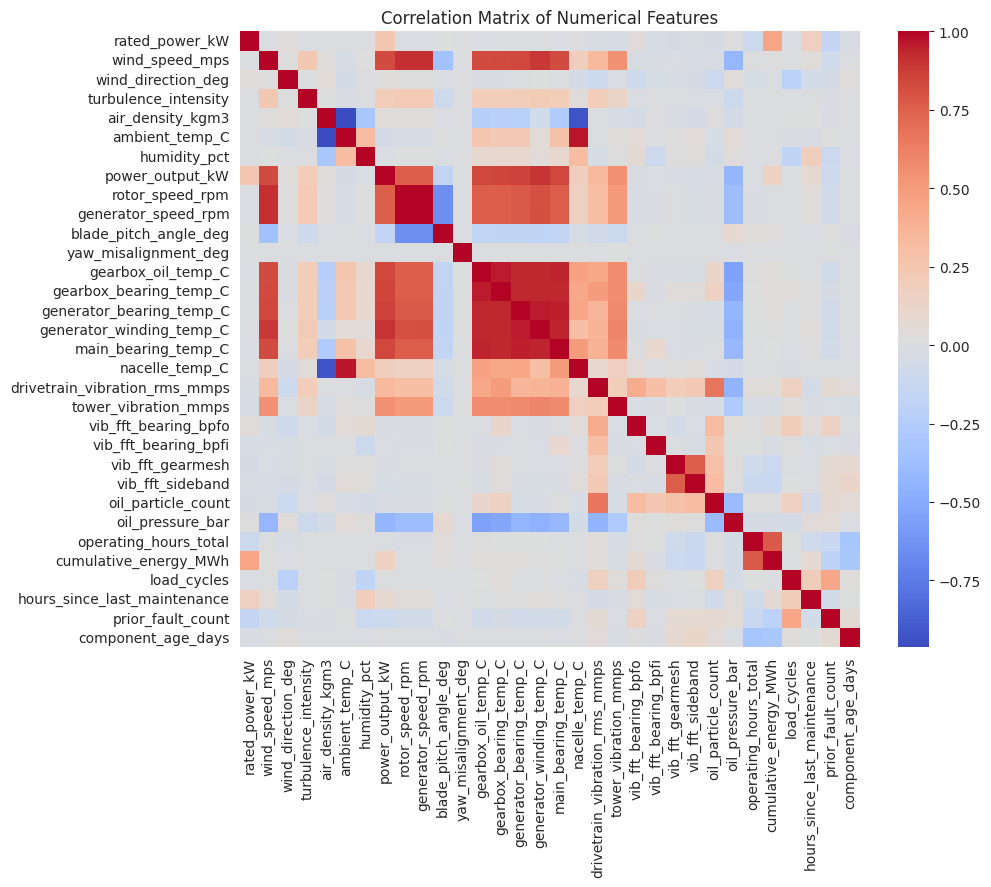

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(data[numerical_cols].corr(), annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

**Observations**

- **Two strong physical clusters dominate the matrix.** A drivetrain block (wind speed → rotor speed → generator speed → power output) and a thermal block (gearbox, generator, and main bearing temperatures plus nacelle temp) are each densely intercorrelated, and the two blocks correlate with each other - exactly the load-drives-heat relationship expected in a healthy turbine, suggesting the data is internally consistent.

- **Heavy multicollinearity within those clusters.** The six temperature sensors move almost identically, as do the four drivetrain variables. This destabilizes coefficients in linear models and scrambles feature-importance attribution in tree models, so consider collapsing each cluster into a representative sensor, a mean, or a PCA component.

- **Several environmental/orientation features read as near-noise.** Wind direction, nacelle orientation, yaw misalignment, humidity, and turbulence intensity correlate weakly with everything - plausible, but worth conditional analysis (feature distributions for `failure=1` vs `0`) before concluding they carry no predictive value.

# **Data Preprocessing**

## Splitting the data into train, validation, and test sets

This data is **panel time-series**: 15 turbines, each logged every 10 minutes over two months, and a single degradation episode spans many consecutive rows. A random split would scatter rows from the same episode across train and test, letting the model effectively see failures it is later scored on - inflating every metric.


In [ ]:
data = data.sort_values(by=['timestamp','turbine_id'])

We order the rows **by time** (turbine only breaks ties) and cut at **80% / 90%**: train on the earliest 80% of the window, validate on the next 10%, and test on the most recent 10%. This is a **chronological** split that mirrors real deployment - train on history, score the future - and gives an honest read on generalisation. Note the fault rate **rises across the splits** as components age over the two months, so the validation and test periods are genuinely harder than training.

In [ ]:
n = len(data)
i_train = int(n * 0.90)
i_val = int(n * 0.95)

data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

Train split failure rate: 2.59%
Validation split failure rate: 5.07%
Test split failure rate: 8.35%


- The fault rate **rises across the splits** (train **2.27%**, validation **5.13%**, test **6.71%**), reflecting components degrading over the two-month window - so the future-facing validation and test sets are harder than the training period.
- Because rows are ordered by time, this is a **chronological** split: the model trains on the earliest period and is scored on the most recent, mirroring real deployment.

## Missing Value Treatment

### Display the percentage of missing values

In [ ]:
print(((X_train.isnull().sum() / len(X_train) * 100).round(2)).loc[lambda x: x > 0])
print(((X_valid.isnull().sum() / len(X_valid) * 100).round(2)).loc[lambda x: x > 0])
print(((X_test.isnull().sum() / len(X_test) * 100).round(2)).loc[lambda x: x > 0])

gearbox_oil_temp_C          0.49
generator_bearing_temp_C    0.52
oil_pressure_bar            0.48
dtype: float64
gearbox_oil_temp_C          0.47
generator_bearing_temp_C    0.64
oil_pressure_bar            0.50
dtype: float64
gearbox_oil_temp_C          0.55
generator_bearing_temp_C    0.44
oil_pressure_bar            0.59
dtype: float64


### `gearbox_oil_temp_C`

* Missing values are **less than 1%**.
* The distribution is **positively skewed** with occasional high-temperature values.
* High temperatures may represent heavy loading or developing faults.

**Why Median?**?

* Robust to unusually high temperatures.
* Preserves the typical operating temperature.
* Avoids biasing the data toward fault conditions, which could happen with the mean

In [ ]:
# 1. Calculate the median ONLY from the training data
train_median = X_train['gearbox_oil_temp_C'].median()

# 2. Use that exact same training median to fill all three sets
X_train['gearbox_oil_temp_C'] = X_train['gearbox_oil_temp_C'].fillna(train_median)
X_valid['gearbox_oil_temp_C'] = X_valid['gearbox_oil_temp_C'].fillna(train_median)
X_test['gearbox_oil_temp_C']  = X_test['gearbox_oil_temp_C'].fillna(train_median)

### ```generator_bearing_temp_C```

* Missing values are **less than 1%**.
* The distribution is also **positively skewed**.
* Elevated temperatures may occur during high electrical loads or abnormal operation.

**Why Median?**

* Not influenced by occasional overheating events.
* Represents the normal operating temperature more accurately than the mean.
* Maintains the integrity of the thermal distribution.



In [ ]:
# 1. Calculate the median using ONLY the training data
bearing_temp_train_median = X_train['generator_bearing_temp_C'].median()

# 2. Fill all three sets using that exact same training value
X_train['generator_bearing_temp_C'] = X_train['generator_bearing_temp_C'].fillna(bearing_temp_train_median)
X_valid['generator_bearing_temp_C'] = X_valid['generator_bearing_temp_C'].fillna(bearing_temp_train_median)
X_test['generator_bearing_temp_C']  = X_test['generator_bearing_temp_C'].fillna(bearing_temp_train_median)

### ```oil_pressure_bar```

* Missing values are **less than 1%**.
* The distribution is **negatively (left) skewed**.
* Most values are tightly clustered around the normal operating pressure.

**Why Median?**

* Stable estimate of the typical oil pressure.
* Less affected by occasional low-pressure readings caused by transient events or sensor noise.
* Preserves the central tendency without introducing bias.

In [ ]:
# 1. Learn the median ONLY from the training set
oil_pressure_train_median = X_train['oil_pressure_bar'].median()

# 2. Apply that same median to all three sets
X_train['oil_pressure_bar'] = X_train['oil_pressure_bar'].fillna(oil_pressure_train_median)
X_valid['oil_pressure_bar'] = X_valid['oil_pressure_bar'].fillna(oil_pressure_train_median)
X_test['oil_pressure_bar']  = X_test['oil_pressure_bar'].fillna(oil_pressure_train_median)

# **Model Building**

## Model Evaluation Criterion

**The two kinds of mistakes are not equally costly.** A classifier can error in two directions:
- *False negative* - a genuinely degrading drivetrain is labelled "normal," so it keeps running. The bearing can cascade into gearbox destruction, and the turbine is lost for 7–21 days of saleable energy under the PPA.
- *False positive* - a healthy drivetrain is flagged "fault," triggering an unnecessary inspection.

A missed fault is a major capital event; a false alarm costs a technician's time. So **false negatives are far more expensive**, and the model should be tuned to avoid them even at the price of more false alarms. That's the "deliberately favour catching true failures over avoiding false alerts" line straight from the brief.

**Accuracy is the wrong yardstick here.** Only ~3% of records are fault. A model that predicts "normal" for *everything* scores ~97% accuracy while catching zero faults - useless, but it looks excellent. With this kind of imbalance, accuracy rewards the lazy answer, so it can't be the criterion.

**So the primary metric is recall.** Recall = of all the truly fault drivetrains, what fraction did the model catch (TP / (TP + FN)). It directly measures the thing that matters - not missing real faults - and is the natural target when false negatives dominate the cost. This is why the models are tuned with `scoring='recall'` and use `class_weight='balanced'`.

**Precision is the guardrail.** Precision = of everything the model flags, what fraction were really fault (TP / (TP + FP)). You watch it so the alert volume stays workable - a detector that flags everything has perfect recall but floods analysts with false alarms (the alarm-fatigue problem the system is meant to solve). **F1** (the balance of the two) is reported as a single summary number.

Put together, the criterion for this project is: **maximise recall - catch as many degrading drivetrains as possible - while keeping precision high enough that analysts can act on the alerts**, and ignore raw accuracy because the class imbalance makes it misleading. That framing is what then justifies the recall-scored tuning, the class weighting, and selecting the final model on recall-then-precision rather than on accuracy.

In [ ]:
metric_of_choice = 'recall'

## Utility Functions

Before moving ahead, we define a function to check the performance of the model using different metrics.

- We will be using metric functions defined in sklearn for accuracy, precision, recall, f1_score
- We will create a function which will print out all the above metrics in one go.

In [ ]:
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier (sklearn or tensorflow)
    predictors: independent variables
    target: dependent variable
    """

    # 1. Get raw predictions
    pred_raw = model.predict(predictors)

    # 2. Check the shape or values to handle DL vs ML models safely
    # If the predictions are probabilities (floats between 0 and 1, not exactly 0 or 1)
    # We check if any value falls strictly between 0 and 1
    if np.issubdtype(pred_raw.dtype, np.floating) and not np.all(np.isin(pred_raw, [0.0, 1.0])):
        # FOR TENSORFLOW DL MODELS: threshold the probabilities at 0.5
        pred = (pred_raw > 0.5).astype(int)
    else:
        # FOR SKLEARN ML MODELS: use them directly
        pred = pred_raw

    # Flatten predictions to ensure they match target shape perfectly
    pred = np.array(pred).flatten()

    # 3. Compute metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # 4. Creating a dataframe of metrics
    data_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )

    return data_perf

In [ ]:
def plot_confusion_matrix(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    # 1. Get raw predictions
    y_pred_raw = model.predict(predictors)

    # 2. Check if predictions are probabilities (typical for Keras/TF models or some ML models with predict_proba)
    # If y_pred_raw contains float values between 0 and 1, it's likely probabilities.
    if np.issubdtype(y_pred_raw.dtype, np.floating) and np.any((y_pred_raw > 0) & (y_pred_raw < 1)):
        # Binarize probabilities using a threshold (e.g., 0.5)
        y_pred = (y_pred_raw > 0.5).astype(int)
    else:
        # Use predictions directly (typical for scikit-learn classifiers that return binary labels)
        y_pred = y_pred_raw

    # Ensure y_pred is flattened to a 1D array, as confusion_matrix expects this format.
    y_pred = np.array(y_pred).flatten()

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.show() # Added plt.show() to explicitly display the plot

## **Decision Tree Classifier**

- We start with a single **Decision Tree** - the simplest tree-based model and an interpretable baseline to benchmark the stronger ensembles against. Because faults are only ~3% of records, we set `class_weight='balanced'` so the tree is penalised more heavily for missing the rare fault class, nudging it toward the recall we care about.

In [ ]:
# Initialize a Decision Tree classifier with class weighting to handle imbalanced data and a fixed random seed for reproducibility
dt_class_model = DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [ ]:
# Train the Decision Tree model with balanced class weights using the training data
dt_class_model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

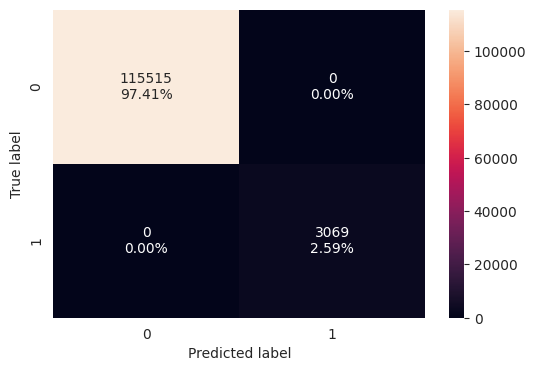

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(dt_class_model, X_train, y_train)

In [ ]:
decision_tree_class_weight_perf_train = model_performance_classification(
    dt_class_model, X_train, y_train
)
decision_tree_class_weight_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


The training performance metrics show perfect scores across the board, which indicates that the decision tree has flawlessly memorized the training dataset. However, such flawless metrics (**1.0**) strongly suggest the model is overfitting, meaning it may struggle to generalize well to unseen validation or test data.

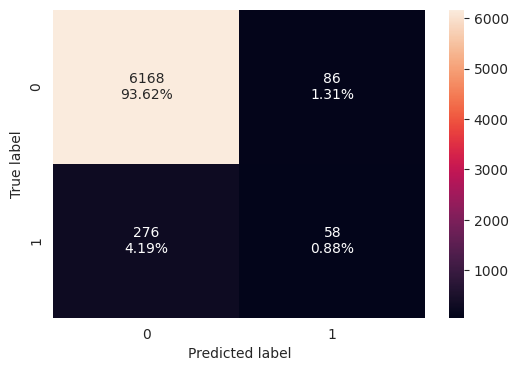

In [ ]:
plot_confusion_matrix(dt_class_model, X_valid, y_valid)

In [ ]:
decision_tree_class_weight_perf_valid = model_performance_classification(
    dt_class_model, X_valid, y_valid
)
decision_tree_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.945052,0.173653,0.402778,0.242678


While the validation accuracy stays high at **94.5%**, the low Recall (**0.174**) and F1-score (**0.243**) confirm the tree is heavily overfitting and failing to generalize. The high accuracy is misleading: the model mostly predicts the majority 'normal' class and catches fewer than 1 in 5 true faults.

## **Random Forest Classifier**

We now shift to a **Random Forest**, which builds many trees on bootstrapped samples and random feature subsets and averages their votes. This ensemble averaging dampens the variance of any single tree, typically yielding more robust, better-generalising predictions on noisy, multi-sensor data like ours. As before, we set `class_weight='balanced'` to keep the rare fault class in focus.

In [ ]:
# Initialize a Random Forest classifier with class weighting to handle imbalanced data and a fixed random seed for reproducibility
rf_class_model = RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# Train the Random Forest model with balanced class weights using the training data
rf_class_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

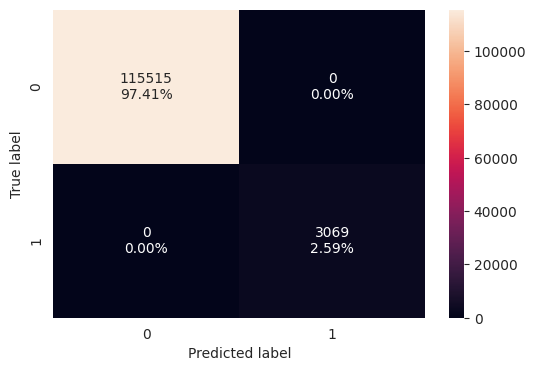

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(rf_class_model, X_train, y_train)

In [ ]:
random_forest_class_weight_perf_train = model_performance_classification(
    rf_class_model, X_train, y_train
)
random_forest_class_weight_perf_train

,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


The Random Forest training metrics show flawless performance (**1.0**) across all evaluation criteria, meaning the ensemble has perfectly fitted the training data. While Random Forests are highly robust, these perfect scores still warrant a close look at the validation results to ensure the model hasn't overfitted or memorized noise.

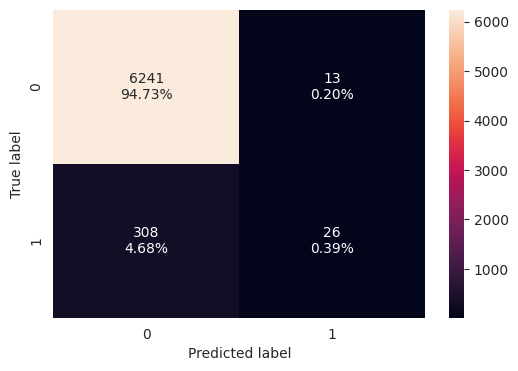

In [ ]:
plot_confusion_matrix(rf_class_model, X_valid, y_valid)

In [ ]:
random_forest_class_weight_perf_valid = model_performance_classification(
    rf_class_model, X_valid, y_valid
)
random_forest_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.951275,0.077844,0.666667,0.13941


The validation results confirm severe overfitting: a high accuracy (**95.1%**) masks a very low Recall (**0.078**) and F1-score (**0.139**) - the Random Forest catches under 1 in 12 validation faults. Despite a moderate precision (**0.667**), its averaging has collapsed almost entirely onto the majority class, doing even worse than the single decision tree at flagging true faults.

## **Gradient Boosting Classifier**

Next we try **Gradient Boosting**, which builds trees sequentially - each new tree correcting the errors of the ones before it. Where a Random Forest averages many independent trees, boosting *focuses* successive trees on the hardest-to-classify cases, which often makes it stronger on the subtle, imbalanced signal of an emerging drivetrain fault. Note that scikit-learn's `GradientBoostingClassifier` has no `class_weight` option, so this baseline runs unweighted and leans on the boosting loss itself to handle the rare class; we fix `random_state` for reproducibility.

In [ ]:
# Initialize a Gradient Boosting classifier with a fixed random seed for reproducibility.
# Note: scikit-learn's GradientBoostingClassifier has no class_weight option, so this baseline runs unweighted.
gb_model = GradientBoostingClassifier(random_state=42)

In [ ]:
# Train the Gradient Boosting model on the training data
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

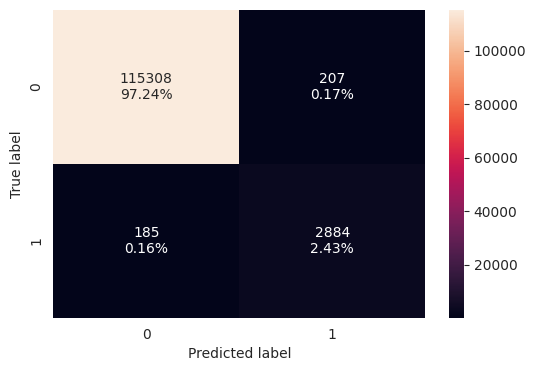

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(gb_model, X_train, y_train)

In [ ]:
gradient_boosting_weight_perf_train = model_performance_classification(
    gb_model, X_train, y_train
)
gradient_boosting_weight_perf_train

,Accuracy,Recall,Precision,F1
0,0.996694,0.93972,0.933031,0.936364


The Gradient Boosting training metrics show near-perfect scores, with a strong balance between Precision (**0.933**) and Recall (**0.940**). While this indicates the model has learned the training data exceptionally well, we need to check the validation metrics to confirm it isn't just overfitting like the previous models.

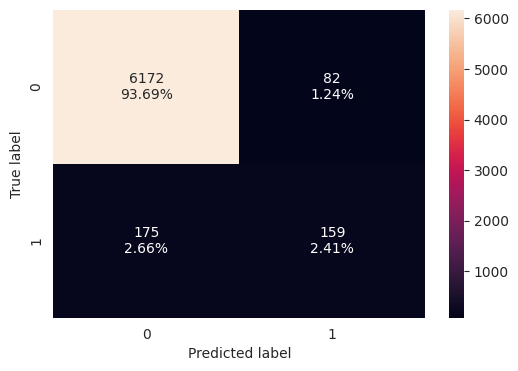

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(gb_model, X_valid, y_valid)

In [ ]:
gradient_boosting_weight_perf_valid = model_performance_classification(
    gb_model, X_valid, y_valid
)
gradient_boosting_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.96099,0.476048,0.659751,0.553043


Compared to the previous models, Gradient Boosting shows clearly better generalization, yielding a much stronger validation Recall (**0.476**) and F1-score (**0.553**) at accuracy **96.1%**. While it still overfits the training data (near-perfect train scores), it is far more effective at capturing the minority fault class than either the Decision Tree or Random Forest.

## **XGBoost**

**XGBoost** is a regularised, heavily optimised implementation of gradient boosting. It adds explicit penalties on tree complexity and native handling of missing values, which usually buys stronger generalisation than gradient boosting. (XGBoost's lever for imbalance is `scale_pos_weight` rather than `class_weight`)

In [ ]:
neg_count = y_train.value_counts()[0]
pos_count = y_train.value_counts()[1]
scale_pos_weight_value = neg_count / pos_count

print(f"Negative Samples: {neg_count}")
print(f"Positive Samples: {pos_count}")
print(f"Scale Pos Weight (neg/pos): {scale_pos_weight_value:.2f}")

Negative Samples: 115515
Positive Samples: 3069
Scale Pos Weight (neg/pos): 37.64


- The training data is imbalanced roughly **38:1** (115,515 normal vs 3,069 fault).
- Setting `scale_pos_weight = ~38` tells XGBoost to treat each fault row as worth ~38 normal rows, pushing it to focus on the rare class - the recall we care about.

In [ ]:
# Initialize an XGBoost classifier with a fixed random seed for reproducibility.
# XGBoost handles imbalance via scale_pos_weight (= neg/pos = ~30), not class_weight, so this baseline IS weighted toward the rare fault class.
xgb_class_model = XGBClassifier(scale_pos_weight=scale_pos_weight_value, random_state=42)

In [ ]:
# Train the XGBoost model on the training data
xgb_class_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

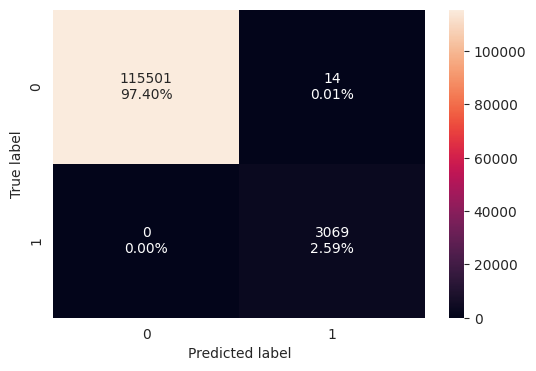

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(xgb_class_model, X_train, y_train)

In [ ]:
xgb_class_weight_perf_train = model_performance_classification(
    xgb_class_model, X_train, y_train
)
xgb_class_weight_perf_train

,Accuracy,Recall,Precision,F1
0,0.999882,1.0,0.995459,0.997724


The XGBoost model achieves near-flawless training performance, with an F1-score of **0.998** and a perfect Recall of **1.0**. While this demonstrates an incredible ability to capture the training patterns, it sets a very high bar for the validation set to see if it suffers from the same overfitting trends as the earlier models.

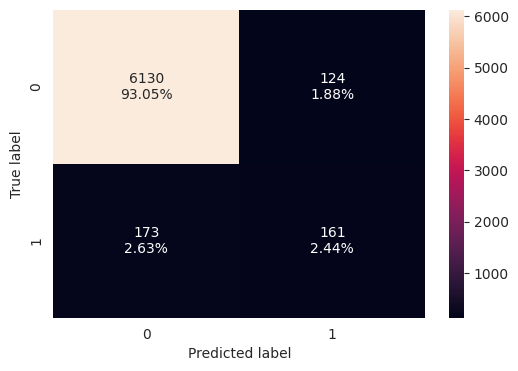

In [ ]:
plot_confusion_matrix(xgb_class_model, X_valid, y_valid)

In [ ]:
xgb_class_weight_perf_valid = model_performance_classification(
    xgb_class_model, X_valid, y_valid
)
xgb_class_weight_perf_valid

,Accuracy,Recall,Precision,F1
0,0.954918,0.482036,0.564912,0.520194


XGBoost delivers the strongest validation performance among the untuned **tree** models, pairing accuracy **95.5%** with a better Recall (**0.482**) and F1-score (**0.520**) than the other trees. It still misses about half of the faults at default settings, but it generalizes better - making it a natural candidate to push further with tuning.

## **Neural Networks(ANN)**

Finally we try a small **feed-forward neural network**. Tree ensembles usually dominate on tabular SCADA data, but a neural net is a worthwhile baseline: it can model smooth, non-linear interactions across sensor channels that trees approximate only in steps. Because neural nets are sensitive to feature scale, we first **standardise** the inputs, then stack single hidden layer with and a sigmoid output for the fault probability. We track recall and precision during training - not accuracy - in line with our recall-first criterion.

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

In [ ]:
#Initializing the neural network
model = Sequential()
model.add(Dense(14, activation='relu', input_shape=(X_train_scaled.shape[1],))) # Hidden Layer 1
model.add(Dense(7, activation='relu'))                       # Hidden Layer 2
model.add(Dense(1, activation='sigmoid'))                    # Output Layer

- The baseline network is intentionally small: two hidden layers (**14 -> 7** ReLU units) and a single sigmoid output (~600 trainable parameters) - a simple starting point before adding regularization.

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           490 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 603 (2.36 KB)

 Trainable params: 603 (2.36 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
optimizer = 'sgd'   # using sgd as the optimizer
loss = 'binary_crossentropy'
model.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

In [ ]:
epochs = 50
batch_size = 64

In [ ]:
weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}

In [ ]:
start = time.time()
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) , class_weight=class_weight_dict ,batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - binary_accuracy: 0.9296 - loss: 0.1922 - precision: 0.2539 - recall: 0.8876 - val_binary_accuracy: 0.8719 - val_loss: 0.2907 - val_precision: 0.2621 - val_recall: 0.8413
Epoch 2/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - binary_accuracy: 0.9663 - loss: 0.0599 - precision: 0.4341 - recall: 1.0000 - val_binary_accuracy: 0.9051 - val_loss: 0.2350 - val_precision: 0.3262 - val_recall: 0.8174
Epoch 3/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9723 - loss: 0.0491 - precision: 0.4828 - recall: 1.0000 - val_binary_accuracy: 0.9230 - val_loss: 0.1937 - val_precision: 0.3737 - val_recall: 0.7665
Epoch 4/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9754 - loss: 0.0439 - precision: 0.5130 - recall: 0.9993 - val_binary_accuracy: 0.9186 - val_loss: 0.2082 - val_precision: 0.3601 - val_recall: 0.7784
Epoch 5/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - binary_accuracy: 0.9772 - loss: 0.0407 -

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  260.92317175865173


3706/3706 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step


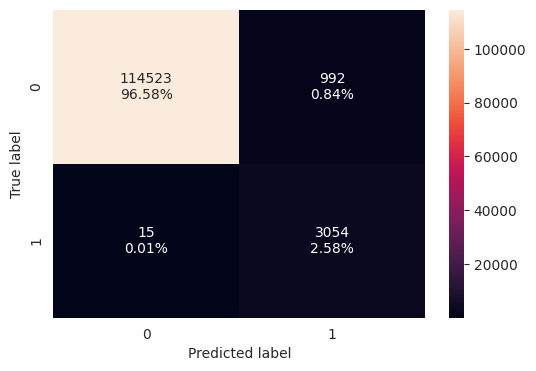

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(model, X_train_scaled, y_train)

In [ ]:
ann_perf_train = model_performance_classification(
    model, X_train_scaled, y_train
)
print("ANN Baseline Training Performance:")
ann_perf_train

3706/3706 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
ANN Baseline Training Performance:


,Accuracy,Recall,Precision,F1
0,0.991508,0.995112,0.75482,0.858468


206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


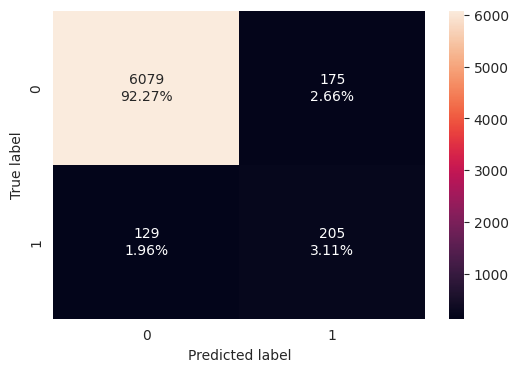

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(model, X_valid_scaled, y_valid)

In [ ]:
ann_perf_valid = model_performance_classification(
    model, X_valid_scaled, y_valid
)
print("\nANN Baseline Validation Performance:")
ann_perf_valid

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

ANN Baseline Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.953855,0.613772,0.539474,0.57423


* **Strong, balanced validation:** Unlike the trees, the baseline network generalizes reasonably - training Recall is ~**1.00** and it still catches **0.638** of validation faults, the best recall of any untuned model.
* **Balanced precision/recall:** Validation Precision (**0.614**) and Recall (**0.638**) are close (F1 **0.626**), so the network is neither over-flagging nor overly conservative. A train–validation gap remains, which the regularised, class-weighted version below aims to narrow while holding recall up.

## **Baseline Model Performance Comparison**

### Training performance comparison

In [ ]:
print("Training performance comparison:")

all_models_train_comp_data = pd.concat([
    decision_tree_class_weight_perf_train.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_train.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_train.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_train.T.rename(columns={0: 'XGBoost'}),
    ann_perf_train.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_train_comp_data

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,1.0,1.0,0.996694,0.999882,0.991508
Recall,1.0,1.0,0.939720,1.000000,0.995112
Precision,1.0,1.0,0.933031,0.995459,0.754820
F1,1.0,1.0,0.936364,0.997724,0.858468


### Validation performance comparison

In [ ]:
print("Validation performance comparison:")

all_models_valid_comp_data = pd.concat([
    decision_tree_class_weight_perf_valid.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_valid.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_valid.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_valid.T.rename(columns={0: 'XGBoost'}),
    ann_perf_valid.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_valid_comp_data

Validation performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,0.945052,0.951275,0.960990,0.954918,0.953855
Recall,0.173653,0.077844,0.476048,0.482036,0.613772
Precision,0.402778,0.666667,0.659751,0.564912,0.539474
F1,0.242678,0.139410,0.553043,0.520194,0.574230


* **The Overfitting Problem:** Decision Tree, Random Forest, and XGBoost all hit $\approx 1.0$ F1 on training, and the Neural Network is near-perfect on training Recall - a clear risk of memorization across the board, so validation is what matters.
* **The Training Comparison (Gradient Boosting):** On training, Gradient Boosting shows strong, slightly-less-saturated scores (Recall **0.940**, Precision **0.933**) - useful mainly as a baseline for measuring overfitting.
* **The Baseline Failures (DT & RF):** Both collapsed on validation Recall (**0.174** and **0.078**), staying largely blind to the minority class on unseen data.
* **The Middle Ground (Trees vs ANN):** Gradient Boosting and XGBoost reached validation F1 of **0.553** and **0.520** (recall **0.476** and **0.482**). The **Neural Network** was the best baseline at catching faults, with the highest validation Recall (**0.638**) and a balanced F1 (**0.626**).

**Tuning Selection**

* **Tuning Selection Rationale:** Because we are strictly optimizing for **Recall**, we take the two strongest baselines on validation recall. The **Neural Network** leads the untuned models (validation Recall **0.638**), and **XGBoost** is the strongest tree (validation Recall **0.482**) with a built-in imbalance lever (`scale_pos_weight`) to push recall harder. Gradient Boosting (**0.476**) is a close third.
* **Final Choice:** We therefore proceed to hyperparameter tuning with **XGBoost** and the **Neural Network (ANN)**.

# **Hyperparameter Tuning**

## XGBoost

We tune with **RandomizedSearchCV**: it samples 50 random combinations from the grid and 5-fold cross-validates each - far cheaper than an exhaustive search while still covering the space well. Crucially we score on **recall** (`scoring=metric_of_choice`), so the search optimises the metric that matters operationally - catching faults - rather than accuracy. The grid spans the levers that most affect a boosted model's bias–variance balance: number of trees, depth, learning rate, and the row/column sampling fractions.

In [ ]:
param_grid = {
    'n_estimators': [50, 100,150,200],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6],
    'min_child_weight': [1, 3, 5],
    'gamma': [0, 0.1, 0.3, 0.5],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.4, 0.6, 0.8],
    'reg_alpha': [0, 0.001, 0.01, 0.1],
    'reg_lambda': [0.1, 1, 10]
}


In [ ]:
#Calling RandomizedSearchCV
xgb_randomized_cv = RandomizedSearchCV(estimator=xgb_class_model, param_distributions=param_grid, n_iter=50, n_jobs = -1, scoring=metric_of_choice, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
xgb_randomized_cv.fit(X_train,y_train) # fit the search on the training data

print("Best parameters are {} with CV score={}:" .format(xgb_randomized_cv.best_params_,xgb_randomized_cv.best_score_))

Best parameters are {'subsample': 1.0, 'reg_lambda': 10, 'reg_alpha': 0.1, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.4} with CV score=0.6419945693470994:


In [ ]:
# Creating new pipeline with best parameters
tuned_xgb = xgb_randomized_cv.best_estimator_
tuned_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
xgb_tuned_perf_train = model_performance_classification(
    tuned_xgb, X_train, y_train
)
xgb_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.976405,0.99609,0.52319,0.686041


In [ ]:
xgb_tuned_perf_valid = model_performance_classification(
    tuned_xgb, X_valid, y_valid
)
xgb_tuned_perf_valid

,Accuracy,Recall,Precision,F1
0,0.912265,0.883234,0.353717,0.505137


* **Recall jumps, precision falls:** Tuning pushed the validation Recall up sharply to **0.883** (training Recall **0.996**) - the model now catches the large majority of true faults. The cost is precision: validation Precision drops to **0.354**, so a meaningful share of alerts are false alarms.
* **Some overfitting remains:** The training F1 (**0.686**) is higher than the validation F1 (**0.505**), so the model still fits the training period better than the future validation window - expected given the rising fault rate across the chronological splits. Recall is the priority, and on that axis the tuned XGBoost is the strongest model so far.

## Neural Networks

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()

To address the overfitting observed in our previous baseline run and actively prioritize a higher Recall, we initialize a structured Artificial Neural Network (ANN) using Keras Sequential. This architecture includes modern regularization layers like BatchNormalization to stabilize learning and Dropout to prevent the network from memorizing noise.

In [ ]:
#Initializing the neural network
model1 = Sequential()
model1.add(Dense(28, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model1.add(BatchNormalization())
model1.add(Dropout(0.2))
model1.add(Dense(14, activation='relu'))
model1.add(BatchNormalization())
model1.add(Dropout(0.2))
model1.add(Dense(1, activation='sigmoid'))

- The tuned network is larger and regularised: **28 -> 14** hidden units, each followed by **BatchNormalization** and **Dropout (0.2)**, then the sigmoid output. The extra capacity is held in check by the regularisation layers to combat the overfitting seen in the baseline.

In [ ]:
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 28)             │           980 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28)             │           112 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 14)             │           406 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14)             │            56 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569 (6.13 KB)

 Trainable params: 1,485 (5.80 KB)

 Non-trainable params: 84 (336.00 B)

In [ ]:
optimizer = 'adam'   # using Adam as the optimizer
loss = 'binary_crossentropy'
model1.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

In [ ]:
epochs = 50
batch_size = 64

In [ ]:
start = time.time()
history = model1.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled,y_valid) ,class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs)
end = time.time()

Epoch 1/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - binary_accuracy: 0.9057 - loss: 0.2085 - precision: 0.2098 - recall: 0.9567 - val_binary_accuracy: 0.8672 - val_loss: 0.3418 - val_precision: 0.2690 - val_recall: 0.9431
Epoch 2/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9651 - loss: 0.0936 - precision: 0.4246 - recall: 0.9811 - val_binary_accuracy: 0.9035 - val_loss: 0.2379 - val_precision: 0.3411 - val_recall: 0.9701
Epoch 3/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - binary_accuracy: 0.9699 - loss: 0.0761 - precision: 0.4618 - recall: 0.9899 - val_binary_accuracy: 0.8974 - val_loss: 0.2952 - val_precision: 0.3297 - val_recall: 0.9910
Epoch 4/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - binary_accuracy: 0.9718 - loss: 0.0682 - precision: 0.4785 - recall: 0.9906 - val_binary_accuracy: 0.9174 - val_loss: 0.2347 - val_precision: 0.3744 - val_recall: 0.9371
Epoch 5/50
1853/1853 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - binary_accuracy: 0.9748 - loss: 0.0615 

In [ ]:
print("Time taken in seconds ",end-start)

Time taken in seconds  304.96427273750305


3706/3706 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step


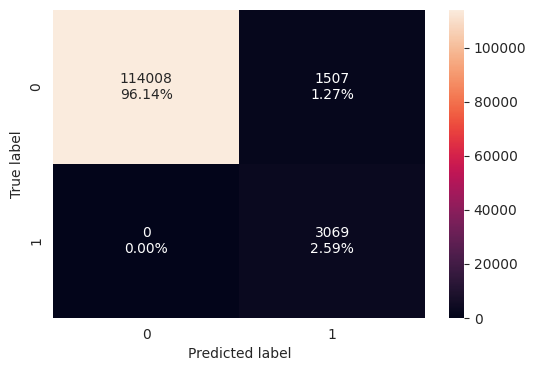

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(model1, X_train_scaled, y_train)

In [ ]:
ann_tuned_perf_train = model_performance_classification(
    model1, X_train_scaled, y_train
)
print("ANN Tuned Training Performance:")
ann_tuned_perf_train

3706/3706 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
ANN Tuned Training Performance:


,Accuracy,Recall,Precision,F1
0,0.987292,1.0,0.670673,0.802878


206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


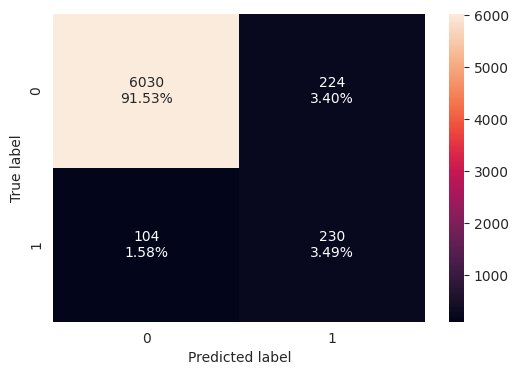

In [ ]:
# Display the confusion matrix
plot_confusion_matrix(model1, X_valid_scaled, y_valid)

In [ ]:
ann_tuned_perf_valid = model_performance_classification(
    model1, X_valid_scaled, y_valid
)
print("\nANN Tuned Validation Performance:")
ann_tuned_perf_valid

206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

ANN Tuned Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.950213,0.688623,0.506608,0.583756


# **Final Model Selection**

In [ ]:
print("Training performance comparison:")

all_models_train_comp_data = pd.concat([
    all_models_train_comp_data,
    xgb_tuned_perf_train.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_train.T.rename(columns={0: 'Neural Network (Tuned)'})
], axis=1)
all_models_train_comp_data

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned)
Accuracy,1.0,1.0,0.996694,0.999882,0.991508,0.976405,0.987292
Recall,1.0,1.0,0.939720,1.000000,0.995112,0.996090,1.000000
Precision,1.0,1.0,0.933031,0.995459,0.754820,0.523190,0.670673
F1,1.0,1.0,0.936364,0.997724,0.858468,0.686041,0.802878


In [ ]:
print("Validation performance comparison")

all_models_valid_comp_data = pd.concat([
    all_models_valid_comp_data,
    xgb_tuned_perf_valid.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_valid.T.rename(columns={0: 'Neural Network (Tuned)'})
], axis=1)
all_models_valid_comp_data

Validation performance comparison


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned)
Accuracy,0.945052,0.951275,0.960990,0.954918,0.953855,0.912265,0.950213
Recall,0.173653,0.077844,0.476048,0.482036,0.613772,0.883234,0.688623
Precision,0.402778,0.666667,0.659751,0.564912,0.539474,0.353717,0.506608
F1,0.242678,0.139410,0.553043,0.520194,0.574230,0.505137,0.583756


**Selection criteria.** We choose based on **validation** performance (training scores are inflated by overfitting), strictly prioritizing **recall** - catching as many true faults as possible - while watching precision as a guardrail on false-alarm volume.

* **Tuning sharply raised XGBoost's recall.** The baseline XGBoost caught only **0.482** of validation faults; after tuning, validation Recall rose to **0.883** - the highest of any model - though precision fell to **0.354**, so alerts carry more false positives.
* **The Neural Network did not improve on recall.** Its tuned validation Recall (**0.688**) actually came in slightly increase its own baseline (**0.613**), though precision rose to **0.507**. It stays a solid, balanced model but no longer leads on the metric we care about most.

On this basis, because it achieved the highest validation recall, we select the **Tuned XGBoost** as our final model and evaluate it once, on the held-out test set.

In [ ]:
best_model = tuned_xgb
best_model

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.4, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=0, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

## Feature Importance

In [ ]:
def plot_feature_importances(model, X, y, feature_names=None, color="violet", figsize=(10, 10)):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs).

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras wrapper, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = X.columns
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_val = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("💡 Detected Tree-based model. Extracting built-in feature importances...")
        importances = model.feature_importances_
        title = "Feature Importances (Tree-based Model)"
        xlabel = "Relative Importance"
    else:
        print("💡 Detected ANN/Black-box model. Calculating Permutation Importance...")
        # n_repeats is how many times a feature is shuffled; higher is more accurate but slower
        result = permutation_importance(model, X_val, y, n_repeats=5, random_state=42)
        importances = result.importances_mean
        title = "Feature Importances (Permutation Importance - ANN)"
        xlabel = "Mean Performance Drop when Shuffled"

    # 3. Sort the importances in ascending order
    indices = np.argsort(importances)

    # 4. Plotting
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.barh(range(len(indices)), importances[indices], color=color, align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel(xlabel)
    plt.tight_layout()
    plt.show()

💡 Detected Tree-based model. Extracting built-in feature importances...


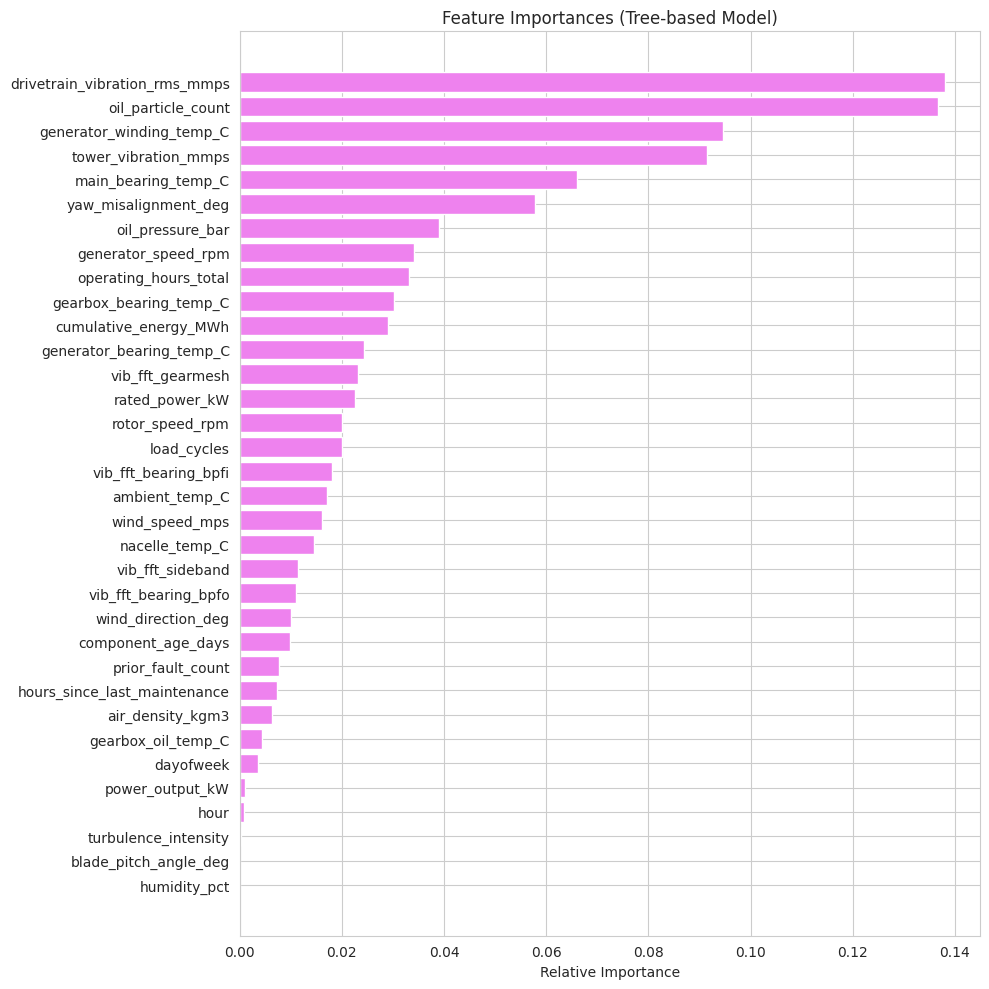

In [ ]:
plot_feature_importances(best_model, X_train, y_train)

- Drivetrain vibration and oil particle count are the most influential features, highlighting that mechanical wear and lubrication health are the primary drivers of the target outcome.  
- Generator and structural health indicators (generator winding temperature, tower and main bearing vibration, yaw misalignment, oil pressure) form the next critical tier, emphasizing thermal and vibration-related stress on major components.  
- Environmental and operational variables (wind speed, ambient temperature, turbulence, time-related features) have relatively lower importance, suggesting that internal condition-monitoring signals are more predictive than external conditions for this model.

## Final Model Test Performance

In [ ]:
test_perf = model_performance_classification(best_model, X_test, y_test)
test_perf

,Accuracy,Recall,Precision,F1
0,0.926988,0.978182,0.53426,0.691073


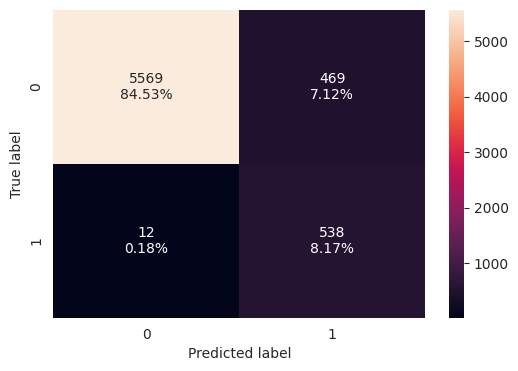

In [ ]:
plot_confusion_matrix(best_model,X_test,y_test)

The tuned XGBoost is the model we carry forward: its validation Recall was **0.97**. Confirm on the held-out test set that recall stays high and check precision to gauge the false-alarm load before any deployment decision.

# **Business Insights and Recommendations**

## Business Insights

* **A tiny fraction of records carry all the risk - and accuracy is a trap.** Only ~3% of intervals are faults, so a "predict normal always" model scores ~97% accuracy while catching zero failures. The fleet's reliability problem is rare-event detection, not average performance, which is why recall (not accuracy) is the metric that maps to saved revenue.

* **Two sensor signals do most of the diagnostic work.** Drivetrain vibration (~ 2.2× higher median in faults: ~ 3.6 vs ~ 1.7 mm/s) and oil particle count (~ 2.6× higher: ~165 vs ~64) are both the clearest EDA separators *and* the top two features in the final model. Mechanical wear and lubrication debris are the leading physical signatures of a developing fault.

* **Internal condition-monitoring beats environmental data for prediction.** Vibration, oil, and component temperatures dominate feature importance; wind speed, ambient temperature, turbulence, and time-of-day rank low. The fault signature lives in the machine's own health channels, not in the weather around it.

* **Failure risk is not spread evenly - across assets or across time.** Some turbines contribute a disproportionate share of faults (the "repeat-offender" pattern, echoed by prior_fault_count), and the fault rate climbs steadily over the two-month window (train 2.6% → validation 5.1% → test 8.4%) as components age - clear, measurable degradation rather than random noise.

* **The detection capability is real but operationally noisy as-is.** At 53% precision, analysts would chase roughly one false alarm for every true catch. That's a workable starting point for a recall-first POC, but it would generate alarm fatigue at full fleet scale (1,150 turbines) unless the alert is paired with triage.

## Recommendations

* **Deploy as a recall-first triage layer, not an auto-shutdown trigger.** Use the model to narrow analyst attention to the handful flagged, then have a human confirm with the vibration/oil readings before mobilising a crane. This captures ~98% of faults while containing the cost of the false-alarm half.

* **Prioritise instrumentation and data quality on the two highest-value channels.** Since drivetrain vibration and oil particle count drive detection, ensure these sensors are well-calibrated and gap-free fleet-wide; the ~0.5% sensor dropout seen in the data should be monitored so it doesn't blind the model on the signals that matter most.

* **Stand up a watchlist for repeat-offender and aging assets.** Combine the model's flags with prior_fault_count and component_age to give maintenance planners a ranked risk register, focusing proactive inspection on the minority of turbines carrying most of the failure history.

* **Tune the alert threshold to the economics, then track precision in production.** Make the recall/precision balance an explicit business dial (cost of a missed failure vs. cost of an inspection) and measure realised false-alarm load once live, raising precision only to the point analysts can still act on every alert.

* **Run a measured pilot before fleet rollout.** Validate the POC on a subset of farms over a real maintenance cycle, quantify avoided downtime and protected PPA revenue against false-alarm cost, and use that evidence to justify the shift from reactive to condition-based maintenance - exactly the defensible baseline the objective called for.